# Terraria Network Analysis
## 1. Introdução e objetivo
Trabalho final de Grafos: estudar fabricação e obtenção no Terraria, seguindo
[os requisitos](../docs/LEIA.md). Refatoramos a primeira etapa existente e ampliamos suas análises.

**Três representações:** `G` mantém ingrediente → produto; `G_full` reúne as entidades
e relações documentadas; `H` é a projeção simples de crafting para comparações acadêmicas.
Uma conexão indica uma relação possível, não um plano completo de fabricação.

Execute as células em ordem na `.venv` criada por `uv sync`.
Toda a implementação e as figuras ficam neste notebook; não há downloads ou gravação de resultados.
Sementes e limites de amostragem são explícitos. Números e interpretações quantitativas são calculados.

In [1]:
import hashlib
import json
import random
import sys
import time
from collections import Counter, defaultdict
from pathlib import Path
from textwrap import fill

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.lines import Line2D

PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / "data/raw/items.json").is_file())
RAW_DIR = PROJECT_ROOT / "data/raw"
assert Path(sys.prefix).resolve() == (PROJECT_ROOT / ".venv").resolve(), "Use o kernel da .venv."
SEED = 42
PATH_SAMPLES = 128
BETWEENNESS_SAMPLES = 256
N_REALIZATIONS = 5
START = time.perf_counter()
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 120)
print(f"Python {sys.version.split()[0]} | NetworkX {nx.__version__} | {sys.executable}")

Python 3.12.13 | NetworkX 3.7 | /home/gengo/Workspace/Faculdade/Conteudos_de_estudo_6_semestre/Grafos/treinando_python_grafos/grafos_network/src/grafos_network/workspace_university/trabalho-3/.venv/bin/python


## 2. Fontes e leitura dos datasets
Fonte: [Doeschi/Terraria-Progress-Tracker](https://github.com/Doeschi/Terraria-Progress-Tracker),
`pipeline/data_readable`, commit `e1726af0908d928a3e2fa437286558827a6dd3b0`.
Os três JSONs anteriores coincidem byte a byte com essa revisão e foram preservados.
Os complementos fornecem entidades, drops e lojas; `meta.json` informa as versões.
Os dados derivam da [Terraria Wiki](https://terraria.wiki.gg/) (CC BY-NC-SA 4.0).

[Contrato dos arquivos](https://github.com/Doeschi/Terraria-Progress-Tracker/blob/e1726af0908d928a3e2fa437286558827a6dd3b0/pipeline/data_readable/README.md):
`obtain` descreve métodos; `categories/subcategories` são classificações.
**`items.biomes` reúne biomas de drops/vendas, não locais de geração de minérios.**
`milestone` é a disponibilidade mais cedo estimada pelo tracker; `milestoneVia` explica a decisão,
inclusive dependências indiretas. Não extraímos drops desse texto.
`conditions` dos itens são restrições agregadas; tokens nas lojas/drops podem conter alternativas.
Preservamos linha e texto originais, sem assumir todos os tokens como requisitos conjuntos.

In [2]:
filenames = ["items", "recipes", "milestones", "biomes", "bosses", "bestiary",
             "drops", "vendors", "shops", "events", "conditions", "meta"]
raw = {name: json.loads((RAW_DIR / f"{name}.json").read_text()) for name in filenames}
source_hashes = {f"{name}.json": hashlib.sha256((RAW_DIR / f"{name}.json").read_bytes()).hexdigest()
                 for name in filenames}
display(pd.DataFrame([{"arquivo": f"{n}.json", "estrutura": type(raw[n]).__name__,
                       "entradas na raiz": len(raw[n]), "SHA256": source_hashes[f"{n}.json"]}
                      for n in filenames]))
print("Versões declaradas pela fonte:", raw["meta"])
items_raw, recipes_raw = raw["items"], raw["recipes"]
items_by_key = {item["key"]: item for item in items_raw}
milestones_by_id = {m["id"]: m for m in raw["milestones"]}
recipe_groups, station_catalog = recipes_raw["groups"], recipes_raw["stations"]
assert len(items_by_key) == len(items_raw), "key duplicada"
assert len(milestones_by_id) == len(raw["milestones"])
fields = ["obtain", "vendors", "biomes", "events", "milestone", "milestoneVia",
          "categories", "subcategories", "conditions"]
display(pd.DataFrame([{"campo": f, "itens com valor": sum(bool(i.get(f)) for i in items_raw),
                       "exemplo": next(i[f] for i in items_raw if i.get(f))} for f in fields]))
print("Seções de recipes.json:", {k: len(v) for k, v in recipes_raw.items()})
print("IDs numéricos repetidos:", sum(c > 1 for c in Counter(i["id"] for i in items_raw).values()))
print("A identidade dos itens é key; nomes e IDs numéricos não são chaves de junção de itens.")

,arquivo,estrutura,entradas na raiz,SHA256
0,items.json,list,6186,ee7318eb8c82142d95b12871766fe8471e715eda0ab33eaf79512db1b96fc20a
1,recipes.json,dict,4,3623d67cbf4ddf3aa5ca97c1c609a7114f56632d156354da3b968d746083ab47
2,milestones.json,list,16,495fb8c8722692782c0ffe765adc2fa702f0f09398fc8ba3afbdd7c75915c2d6
3,biomes.json,list,18,ac5677d59853bc8f3de60d7024d824018e583971fb567779045d3fed4c4a79c1
4,bosses.json,dict,3,0209fd589d7df8190371d82c985a5a67c495d95f13aa90a7271ab60af2d4a0cf
5,bestiary.json,dict,2,299016cf1a66b7d1bb79f61f5c793368e5235d6fd6d24c89c1d9c6e0133668a5
6,drops.json,dict,4,ac1e46a564f2dc5b820738104734e7ab71e90572117f9b48f033f3a47244e2f6
7,vendors.json,list,24,a7658362f552e761043386ef659cc0d592804d72202aa3d7f18938d8700e8f79
8,shops.json,dict,795,917719526b8e3cf048eb5070949ca8f8500a7deaafccb368ba8fa4c62c633f65
9,events.json,list,18,a30b6171b75131341024839b7a84274d9a815044d69d46cc6cb63b9ba771e503


Versões declaradas pela fonte: {'dataVersion': '2026-10-08', 'gameVersion': '1.4.5', 'updates': [{'dataVersion': '2026-10-08', 'added': ['SharpTears'], 'removed': [], 'renamed': {}}]}


,campo,itens com valor,exemplo
0,obtain,6186,[crafted]
1,vendors,787,"[merchant, skeleton-merchant, dryad, zoologist]"
2,biomes,530,[underground]
3,events,545,"[rain, christmas]"
4,milestone,6136,start
5,milestoneVia,6097,Crafted
6,categories,6186,[tool]
7,subcategories,5999,[pickaxe]
8,conditions,267,[night]


Seções de recipes.json: {'stations': 42, 'groups': 34, 'recipes': 3655, 'shimmer': 287}
IDs numéricos repetidos: 9
A identidade dos itens é key; nomes e IDs numéricos não são chaves de junção de itens.


## 3. Construção do grafo de crafting
Mantemos a política anterior: receitas sem `platforms` não têm restrição explícita.
Produtos e opções são filtrados para desktop. Os JSONs não são modificados.
A receita conserva os campos originais e acrescenta `recipe_id` (posição no arquivo),
ingredientes resolvidos e definições das estações.

Slots de uma receita são **AND**; opções do mesmo slot e receitas diferentes são **OR**.
`G` guarda dependências possíveis e suas ocorrências em `uses`.
Quantidade pertence ao slot, não é peso ou custo de aresta.

In [3]:
PLATFORM = "desktop"

def supports_platform(record):
    return PLATFORM in record.get("platforms", [PLATFORM])

def ingredient_options(slot):
    return [slot["item"]] if "item" in slot else recipe_groups[slot["group"]]["items"]

# Integridade: chaves, referências e quantidades positivas.
for group in recipe_groups.values():
    assert group["items"] and set(group["items"]) <= items_by_key.keys()
for station in station_catalog.values():
    assert set(station.get("items", [])) <= items_by_key.keys()
for recipe in recipes_raw["recipes"]:
    assert recipe["result"] in items_by_key and recipe["amount"] > 0
    assert set(recipe["stations"]) <= station_catalog.keys()
    assert recipe["ingredients"]
    for slot in recipe["ingredients"]:
        assert ("item" in slot) != ("group" in slot)
        assert slot["amount"] > 0 and set(ingredient_options(slot)) <= items_by_key.keys()

recipes_desktop, excluded_recipes = {}, []
for rid, recipe in enumerate(recipes_raw["recipes"]):
    resolved = [{**slot, "options": [key for key in ingredient_options(slot)
                                     if supports_platform(items_by_key[key])]}
                for slot in recipe["ingredients"]]
    if not (supports_platform(recipe) and supports_platform(items_by_key[recipe["result"]])
            and all(slot["options"] for slot in resolved)):
        excluded_recipes.append(rid)
        continue
    recipes_desktop[rid] = {**recipe, "recipe_id": rid, "resolved_ingredients": resolved,
                           "station_requirements": [{"name": s, "definition": station_catalog[s]}
                                                    for s in recipe["stations"]]}
print(f"{len(recipes_desktop)} receitas selecionadas; {len(excluded_recipes)} excluídas por plataforma.")

3655 receitas selecionadas; 0 excluídas por plataforma.


In [4]:
G = nx.DiGraph(name="Terraria — dependências de crafting desktop", source_hashes=source_hashes)
for rid, recipe in recipes_desktop.items():
    product = recipe["result"]
    for slot_index, slot in enumerate(recipe["resolved_ingredients"]):
        for ingredient in slot["options"]:
            for key in (ingredient, product):
                G.add_node(key, **items_by_key[key])
            if not G.has_edge(ingredient, product):
                G.add_edge(ingredient, product, recipe_ids=[], uses=[])
            edge = G[ingredient][product]
            if rid not in edge["recipe_ids"]:
                edge["recipe_ids"].append(rid)
            edge["uses"].append({"recipe_id": rid, "ingredient_index": slot_index,
                                 "amount": slot["amount"], "group": slot.get("group")})

expected_uses = {(key, r["result"], rid, j, s["amount"], s.get("group"))
                 for rid, r in recipes_desktop.items()
                 for j, s in enumerate(r["resolved_ingredients"]) for key in s["options"]}
actual_uses = [(u, v, s["recipe_id"], s["ingredient_index"], s["amount"], s["group"])
               for u, v, d in G.edges(data=True) for s in d["uses"]]
assert len(actual_uses) == len(expected_uses) and set(actual_uses) == expected_uses
assert all(G.nodes[k] == items_by_key[k] for k in G)
assert len(G) >= 300 and nx.number_of_isolates(G) == 0
for key in ("IronBar", "LeadBar"):
    assert any(u["group"] == "Any Iron Bar" and u["amount"] == 2
               for u in G[key]["LesionChest"]["uses"])
night_recipes = [r for r in recipes_desktop.values() if r["result"] == "NightsEdge"]
assert {s["item"] for r in night_recipes for s in r["ingredients"] if "item" in s} >= {"LightsBane", "BloodButcherer"}
print(f"G validado: {len(G):,} vértices, {G.number_of_edges():,} arestas.")

G validado: 3,773 vértices, 7,045 arestas.


## 4. Expansão dos relacionamentos
Adicionamos bestiário, bosses, drops, vendedores, lojas, biomas, eventos, condições e versão.
Não existe arquivo específico de geração geológica nessa base. `ore` identifica um minério,
mas não comprova sua geração em um bioma: essa lacuna permanece explícita.

Junções de criaturas usam nome exato único (inclusive páginas coletivas) ou `npcId` com página compatível.
Fontes sem correspondência inequívoca permanecem como `drop_source`, sem inventar espécie.
Partes de bosses e sacolas continuam distintas. `bosses.sources` é agrupamento de fontes:
não significa que o boss dropa diretamente o conteúdo de uma sacola.

Localização de criaturas vem do bestiário/fontes de drop. Para NPCs da cidade pode representar
associação/preferência: usamos `associa_npc`, sem alegar spawn.
Bioma de venda/drop permanece na linha de origem; só requisitos de receita criam condições de crafting.
A equivalência Ecto Mist–Graveyard é documentada na [Wiki](https://terraria.wiki.gg/wiki/Ecto);
Snow Biome–Snow corresponde ao requisito explícito do dataset.

In [5]:
biomes = {x["id"]: x for x in raw["biomes"]}
events = {x["id"]: x for x in raw["events"]}
vendors = {x["id"]: x for x in raw["vendors"]}
bosses = {x["id"]: x for x in raw["bosses"]["bosses"]}
conditions = {x["id"]: x for x in raw["conditions"]["conditions"]}
bestiary = {x["id"]: x for x in raw["bestiary"]["entries"]}
drop_sources = raw["drops"]["sources"]
desktop_items = {k: v for k, v in items_by_key.items() if supports_platform(v)}
boss_by_name = {b["name"]: k for k, b in bosses.items()}
vendor_by_name = {v["name"]: k for k, v in vendors.items()}
be_by_name = defaultdict(list)
be_by_npc_id = {b["npcId"]: b for b in bestiary.values()}
for entry in bestiary.values():
    be_by_name[entry["name"]].append(entry)

def bestiary_node(entry):
    if entry["name"] in boss_by_name:
        return f"boss:{boss_by_name[entry['name']]}"
    if entry["name"] in vendor_by_name:
        return f"npc:{vendor_by_name[entry['name']]}"
    kind = "npc" if entry["type"] == "town" else entry["type"]
    return f"{kind}:{entry['id']}"

source_nodes, identity_unresolved = {}, []
for sid, source in drop_sources.items():
    candidates = be_by_name[source["name"]]
    match = candidates[0] if len(candidates) == 1 else be_by_npc_id.get(source.get("npcId"))
    if len(candidates) != 1 and match and match["url"] != source["url"]:
        match = None
    if source["kind"] != "npc":
        node = f"container:{sid}"
    elif source["name"] in boss_by_name:
        node = f"boss:{boss_by_name[source['name']]}"
    elif match:
        node = bestiary_node(match)
    else:
        node = f"drop_source:{sid}"
        identity_unresolved.append({"source": sid, "nome": source["name"],
                                    "motivo": "sem correspondência única no bestiário"})
    source_nodes[sid] = node
print("Fontes sem junção com bestiário (preservadas):", len(identity_unresolved))
display(pd.DataFrame(identity_unresolved).head(12))

Fontes sem junção com bestiário (preservadas): 38


,source,nome,motivo
0,mythical-wyvern,Mythical Wyvern,sem correspondência única no bestiário
1,shadow-hammer,Shadow Hammer,sem correspondência única no bestiário
2,crimson-heart,Crimson Heart,sem correspondência única no bestiário
3,shadow-orb,Shadow Orb,sem correspondência única no bestiário
4,spiked-slime,Spiked Slime,sem correspondência única no bestiário
5,mechdusa,Mechdusa,sem correspondência única no bestiário
6,jungle-mimic,Jungle Mimic,sem correspondência única no bestiário
7,slime,Slime,sem correspondência única no bestiário
8,dart-trap-slime,Dart Trap Slime,sem correspondência única no bestiário
9,voice-accessory-slime,Voice accessory Slime,sem correspondência única no bestiário


## 5. Construção do grafo completo
`G_full` é um `MultiDiGraph`. Cada nó tem `uid`, `name`, `type` e `records` (registros originais
com proveniência). Arestas têm `relation`, `source` (arquivo/caminho) e atributos pertinentes.
Receitas usam IDs locais, não IDs oficiais do jogo.

Ingrediente → receita guarda slot, quantidade, grupo e `choice="one_of"`.
A receita completa permanece no nó e em `recipes_desktop`: requisitos AND e alternativas OR
continuam recuperáveis. Estações equivalentes são alternativas; estações listadas na receita são conjuntas.
Condições ambientais têm tipo `condition`, inclusive By Hand, conforme a fonte.
Não criamos `weight`.

Progressão usa `disponivel_desde`, como estimativa do tracker, e bosses que definem marcos com o mesmo ID.
Marcos compostos permanecem descritos no catálogo: não inventamos uma ordem obrigatória entre bosses.

`unlockedBy` do bestiário significa desbloquear sua **entrada no bestiário**, não liberar
o spawn da criatura; permanece no registro original. `milestones.count` conta itens,
não duração nem custo. Grupos probabilísticos de drops ficam em `G_full.graph["drop_groups"]`.


In [6]:
G_full = nx.MultiDiGraph(name="Terraria — relações documentadas", source_hashes=source_hashes,
                         drop_groups=raw["drops"]["groups"])
unresolved, excluded_relations = [], []

def add_entity(uid, name, record, source):
    if uid not in G_full:
        G_full.add_node(uid, uid=uid, name=name, type=uid.split(":", 1)[0], records={})
    G_full.nodes[uid]["records"][source] = record

def link(u, v, relation, source, **attributes):
    # NetworkX criaria nós silenciosamente; esta checagem impede referências fantasmas.
    if u not in G_full or v not in G_full:
        unresolved.append({"origem": u, "destino": v, "relação": relation, "fonte": source})
        return
    G_full.add_edge(u, v, relation=relation, source=source, **attributes)

for key, item in desktop_items.items():
    add_entity(f"item:{key}", item["name"], item, f"items.json/{key}")
    G_full.nodes[f"item:{key}"]["is_ore"] = "ore" in item["subcategories"]
for kind, catalog, file in [("biome", biomes, "biomes.json"), ("event", events, "events.json"),
                            ("npc", vendors, "vendors.json"), ("boss", bosses, "bosses.json/bosses"),
                            ("milestone", milestones_by_id, "milestones.json"),
                            ("condition", conditions, "conditions.json/conditions")]:
    for key, record in catalog.items():
        add_entity(f"{kind}:{key}", record["name"], record, f"{file}/{key}")
for key, entry in bestiary.items():
    if supports_platform(entry):
        add_entity(bestiary_node(entry), entry["name"], entry, f"bestiary.json/entries/{key}")
for sid, source in drop_sources.items():
    if supports_platform(source):
        add_entity(source_nodes[sid], source["name"], source, f"drops.json/sources/{sid}")
for name, definition in station_catalog.items():
    kind = "condition" if definition.get("condition") else "station"
    add_entity(f"{kind}:{name}", name, definition, f"recipes.json/stations/{name}")
    for key in definition.get("items", []):
        if key in desktop_items:
            link(f"item:{key}", f"{kind}:{name}", "fornece_estacao", f"recipes.json/stations/{name}",
                 choice="one_of")

In [7]:
craft_biomes = {"Snow Biome": "snow", "Ecto Mist": "graveyard"}
for rid, recipe in recipes_desktop.items():
    node, source = f"recipe:{rid}", f"recipes.json/recipes/{rid}"
    add_entity(node, f"Receita {rid}: {items_by_key[recipe['result']]['name']}", recipe, source)
    link(node, f"item:{recipe['result']}", "produz", source, amount=recipe["amount"])
    for j, slot in enumerate(recipe["resolved_ingredients"]):
        for option in slot["options"]:
            link(f"item:{option}", node, "ingrediente_de", source, slot=j,
                 amount=slot["amount"], group=slot.get("group"), choice="one_of")
    for station in recipe["stations"]:
        is_condition = station_catalog[station].get("condition", False)
        kind = "condition" if is_condition else "station"
        link(f"{kind}:{station}", node, "exige_condicao" if is_condition else "utilizada_em", source)
        if station in craft_biomes:
            link(f"biome:{craft_biomes[station]}", node, "condicao_de_crafting", source,
                 condition=station, interpretation_source="https://terraria.wiki.gg/wiki/Ecto" if
                 station == "Ecto Mist" else "recipes.json/stations/Snow Biome")

shimmer_rows = set()
for index, row in enumerate(recipes_raw["shimmer"]):
    for key in ingredient_options(row):
        if key in desktop_items and row["result"] in desktop_items:
            link(f"item:{key}", f"item:{row['result']}", "shimmer", f"recipes.json/shimmer/{index}",
                 amount=row["amount"], conditions=row.get("conditions", []), record=row,
                 group=row.get("group"), choice="one_of")
            shimmer_rows.add(index)
        else:
            excluded_relations.append({"source": f"recipes.json/shimmer/{index}", "reason": "plataforma"})

for key, item in desktop_items.items():
    uid, source = f"item:{key}", f"items.json/{key}"
    for field, kind, relation in [("biomes", "biome", "associado_a_obtencao"),
                                   ("events", "event", "obtido_em_evento"),
                                   ("conditions", "condition", "restricao_do_item")]:
        for value in item[field]:
            link(f"{kind}:{value}", uid, relation, source + f"/{field}")
    if item.get("milestone"):
        link(f"milestone:{item['milestone']}", uid, "disponivel_desde", source + "/milestone",
             interpretation="estimativa do tracker", explanation=item.get("milestoneVia"))
for key in sorted(bosses.keys() & milestones_by_id.keys()):
    link(f"boss:{key}", f"milestone:{key}", "define_marco", f"milestones.json/{key}",
         interpretation="mesmo id; não ordena outros bosses")

In [8]:
for key, entry in bestiary.items():
    if not supports_platform(entry):
        continue
    node, source = bestiary_node(entry), f"bestiary.json/entries/{key}"
    relation = "associa_npc" if entry["type"] == "town" else "permite_encontro"
    for biome in entry["biomes"]:
        link(f"biome:{biome}", node, relation, source + "/biomes")
    for event in entry["events"]:
        link(f"event:{event}", node, "aparece_em_evento", source + "/events")
for sid, row in drop_sources.items():
    if not supports_platform(row):
        continue
    node, source = source_nodes[sid], f"drops.json/sources/{sid}"
    if row["kind"] == "npc":
        relation = "associa_npc" if G_full.nodes[node]["type"] == "npc" else "permite_encontro"
        for biome in row.get("biomes", []):
            link(f"biome:{biome}", node, relation, source + "/biomes")
        for event in row.get("events", []):
            link(f"event:{event}", node, "aparece_em_evento", source + "/events")
for bid, boss in bosses.items():
    for sid in boss["sources"]:
        if supports_platform(drop_sources[sid]) and source_nodes[sid] != f"boss:{bid}":
            link(f"boss:{bid}", source_nodes[sid], "agrupa_fonte_de_drop", f"bosses.json/bosses/{bid}",
                 source_id=sid, interpretation="agrupamento; não é drop direto")

# Uma aresta por linha: probabilidades, variantes, dificuldade e grupos permanecem no registro.
drop_rows_added = set()
for item, rows in raw["drops"]["items"].items():
    for j, row in enumerate(rows):
        source = f"drops.json/items/{item}/{j}"
        if item not in desktop_items or not supports_platform(drop_sources[row["source"]]):
            excluded_relations.append({"source": source, "reason": "plataforma"})
            continue
        kind = drop_sources[row["source"]]["kind"]
        link(source_nodes[row["source"]], f"item:{item}", "dropa" if kind == "npc" else "contem_drop",
             source, record=row, quantity=row.get("quantity"), chance=row.get("chance"),
             conditions=row.get("conditions", []))
        drop_rows_added.add((item, j))
shop_rows_added = set()
for item, rows in raw["shops"].items():
    for j, row in enumerate(rows):
        source = f"shops.json/{item}/{j}"
        if item not in desktop_items:
            excluded_relations.append({"source": source, "reason": "plataforma"})
            continue
        link(f"npc:{row['vendor']}", f"item:{item}", "vende", source,
             record=row, conditions=row.get("conditions", []), condition_text=row.get("text"))
        shop_rows_added.add((item, j))
shop_pairs = {(raw["shops"][item][j]["vendor"], item) for item, j in shop_rows_added}
for item, record in desktop_items.items():
    for vendor in record["vendors"]:
        if (vendor, item) not in shop_pairs:
            link(f"npc:{vendor}", f"item:{item}", "vende", f"items.json/{item}/vendors",
                 interpretation="sem linha detalhada de loja")

# Biomas mencionados nas próprias linhas: contexto da oferta/drop, não mineração ou crafting.
for item, j in sorted(shop_rows_added):
    row = raw["shops"][item][j]
    for biome in row.get("biomes", []):
        link(f"biome:{biome}", f"item:{item}", "contexto_de_venda", f"shops.json/{item}/{j}",
             vendor=row["vendor"], record=row, interpretation="ver texto e alternativas da oferta")
for item, j in sorted(drop_rows_added):
    row = raw["drops"]["items"][item][j]
    for biome in row.get("biomes", []):
        link(f"biome:{biome}", f"item:{item}", "contexto_de_drop", f"drops.json/items/{item}/{j}",
             record=row, interpretation="restrição desta linha de drop")


## 6. Validação e estatísticas gerais
Verificamos referências, equivalência da camada de crafting, cobertura e preservação de registros.
Fontes sem identificação no bestiário têm nós próprios e não são referências quebradas.
Itens não obtíveis permanecem marcados como na fonte; não inventamos formas de obtenção.
Duplicatas de evidência podem coexistir no multigrafo: suas arestas contam registros relacionais.

Componentes **fracas** ignoram direção; **fortes** exigem caminhos nos dois sentidos.
Isolados de catálogo não são automaticamente erros.

In [9]:
assert not unresolved, f"Referências inválidas: {unresolved[:5]}"
assert all(n == d["uid"] and d["name"] and d["type"] and d["records"] for n, d in G_full.nodes(data=True))
assert all(d["relation"] and d["source"] and "weight" not in d for *_, d in G_full.edges(data=True))
for source in drop_sources.values():
    assert set(source.get("biomes", [])) <= biomes.keys()
    assert set(source.get("events", [])) <= events.keys()
for rows in [*raw["drops"]["items"].values(), *raw["shops"].values()]:
    for row in rows:
        assert set(row.get("conditions", [])) <= conditions.keys()
        assert set(row.get("biomes", [])) <= biomes.keys()
        assert set(row.get("events", [])) <= events.keys()
for row in recipes_raw["shimmer"]:
    assert set(row.get("conditions", [])) <= conditions.keys()
    assert row["result"] in items_by_key and row["amount"] > 0

# Projeção dirigida pelos caminhos Item -> Receita -> Item; ordenação fixa.
D_craft = nx.DiGraph()
for rid in recipes_desktop:
    rnode = f"recipe:{rid}"
    ingredients = sorted({u for u, _, d in G_full.in_edges(rnode, data=True) if d["relation"] == "ingrediente_de"})
    products = sorted({v for _, v, d in G_full.out_edges(rnode, data=True) if d["relation"] == "produz"})
    D_craft.add_edges_from((u, v) for u in ingredients for v in products)
assert set(D_craft.edges) == {(f"item:{u}", f"item:{v}") for u, v in G.edges}
assert sum(d["relation"] == "ingrediente_de" for *_, d in G_full.edges(data=True)) == len(expected_uses)
assert sum(d["relation"] == "produz" for *_, d in G_full.edges(data=True)) == len(recipes_desktop)
assert sum(d["relation"] in {"dropa", "contem_drop"} for *_, d in G_full.edges(data=True)) == len(drop_rows_added)
for u, v, data in G_full.edges(data=True):
    record = data.get("record")
    if data["relation"] in {"dropa", "contem_drop"}:
        item, row_index = data["source"].split("/")[-2:]
        assert record == raw["drops"]["items"][item][int(row_index)]
        assert u == source_nodes[record["source"]] and v == f"item:{item}"
        groups = record.get("group", {})
        group_ids = groups.values() if isinstance(groups, dict) else [groups]
        assert set(group_ids) <= raw["drops"]["groups"].keys()
    elif data["relation"] == "vende" and record:
        item, row_index = data["source"].split("/")[-2:]
        assert record == raw["shops"][item][int(row_index)]
        assert u == f"npc:{record['vendor']}" and v == f"item:{item}"
assert len(drop_rows_added) + sum(x["source"].startswith("drops.json/items/") for x in excluded_relations) == sum(map(len, raw["drops"]["items"].values()))
assert all(G_full.nodes[f"recipe:{rid}"]["records"][f"recipes.json/recipes/{rid}"] == r for rid, r in recipes_desktop.items())
print("Validação: referências, registros originais, cobertura de drops, crafting e ausência de pesos — OK.")

summary = pd.DataFrame([{"grafo": name, "vértices": len(graph), "arestas": graph.number_of_edges(),
                         "componentes fracas": nx.number_weakly_connected_components(graph),
                         "componentes fortes": nx.number_strongly_connected_components(graph),
                         "isolados": nx.number_of_isolates(graph)} for name, graph in [("G", G), ("G_full", G_full)]])
display(summary.set_index("grafo"))
node_counts = pd.Series(Counter(nx.get_node_attributes(G_full, "type").values())).sort_values(ascending=False)
relation_counts = pd.Series(Counter(d["relation"] for *_, d in G_full.edges(data=True))).sort_values(ascending=False)
display(node_counts.rename("vértices").to_frame())
display(relation_counts.rename("arestas").to_frame())
coverage = pd.DataFrame([
    ("itens desktop", len(desktop_items), len(items_raw)),
    ("receitas", len(recipes_desktop), len(recipes_raw["recipes"])),
    ("linhas de shimmer", len(shimmer_rows), len(recipes_raw["shimmer"])),
    ("linhas de drops", len(drop_rows_added), sum(map(len, raw["drops"]["items"].values()))),
    ("linhas de lojas", len(shop_rows_added), sum(map(len, raw["shops"].values()))),
    ("entradas do bestiário", sum(supports_platform(e) for e in bestiary.values()), len(bestiary)),
    ("fontes de drop", sum(supports_platform(e) for e in drop_sources.values()), len(drop_sources)),
], columns=["dados", "incluídos", "originais"])
coverage["cobertura (%)"] = 100 * coverage["incluídos"] / coverage["originais"]
display(coverage)
print("Referências de arestas não resolvidas:", len(unresolved), "| Exclusões por plataforma:", len(excluded_relations))
print("Isolados de G_full (primeiros):", list(nx.isolates(G_full))[:12])
print("Fontes sem junção ao bestiário:", len(identity_unresolved))
active_unresolved_identities = [row for row in identity_unresolved if source_nodes[row["source"]] in G_full]
print("Fontes desktop sem junção:", len(active_unresolved_identities))
display(pd.DataFrame(excluded_relations))
display(pd.DataFrame([{"campo": field, "não preenchidos": sum(not i.get(field) for i in items_raw)}
                      for field in ["milestone", "milestoneVia", "biomes"]]))


Validação: referências, registros originais, cobertura de drops, crafting e ausência de pesos — OK.


,vértices,arestas,componentes fracas,componentes fortes,isolados
grafo,,,,,
G,3773,7045,62,3423,0
G_full,10672,28710,85,9134,83


,vértices
item,6184
recipe,3655
enemy,385
critter,88
container,87
condition,75
npc,40
drop_source,37
station,35
boss,34


,arestas
ingrediente_de,7179
disponivel_desde,6135
produz,3655
utilizada_em,3211
dropa,1849
contem_drop,1828
vende,822
associado_a_obtencao,734
exige_condicao,587
permite_encontro,582


,dados,incluídos,originais,cobertura (%)
0,itens desktop,6184,6186,99.967669
1,receitas,3655,3655,100.000000
2,linhas de shimmer,287,287,100.000000
3,linhas de drops,3677,3680,99.918478
4,linhas de lojas,817,817,100.000000
5,entradas do bestiário,546,546,100.000000
6,fontes de drop,487,488,99.795082


Referências de arestas não resolvidas: 0 | Exclusões por plataforma: 3
Isolados de G_full (primeiros): ['item:BluePresent', 'item:GreenPresent', 'item:YellowPresent', 'item:VortexAxe', 'item:VortexChainsaw', 'item:VortexHammer', 'item:NebulaAxe', 'item:NebulaChainsaw', 'item:NebulaHammer', 'item:SolarFlareAxe', 'item:SolarFlareChainsaw', 'item:SolarFlareHammer']
Fontes sem junção ao bestiário: 38
Fontes desktop sem junção: 37


,source,reason
0,drops.json/items/CobaltBar/0,plataforma
1,drops.json/items/MythrilBar/0,plataforma
2,drops.json/items/AdamantiteBar/0,plataforma


,campo,não preenchidos
0,milestone,50
1,milestoneVia,89
2,biomes,5656


## 7. Visualização das relações
A cadeia da Terra Blade inclui **todos os ancestrais**, minérios e ciclos reais.
`multipartite_layout` substitui o posicionamento e recorte manual das setas. As colunas seguem a
distância mínima ao alvo, não uma ordem obrigatória. Quantidades e requisitos ficam na tabela.
Para a rede expandida mostramos um pequeno recorte com referências reais.

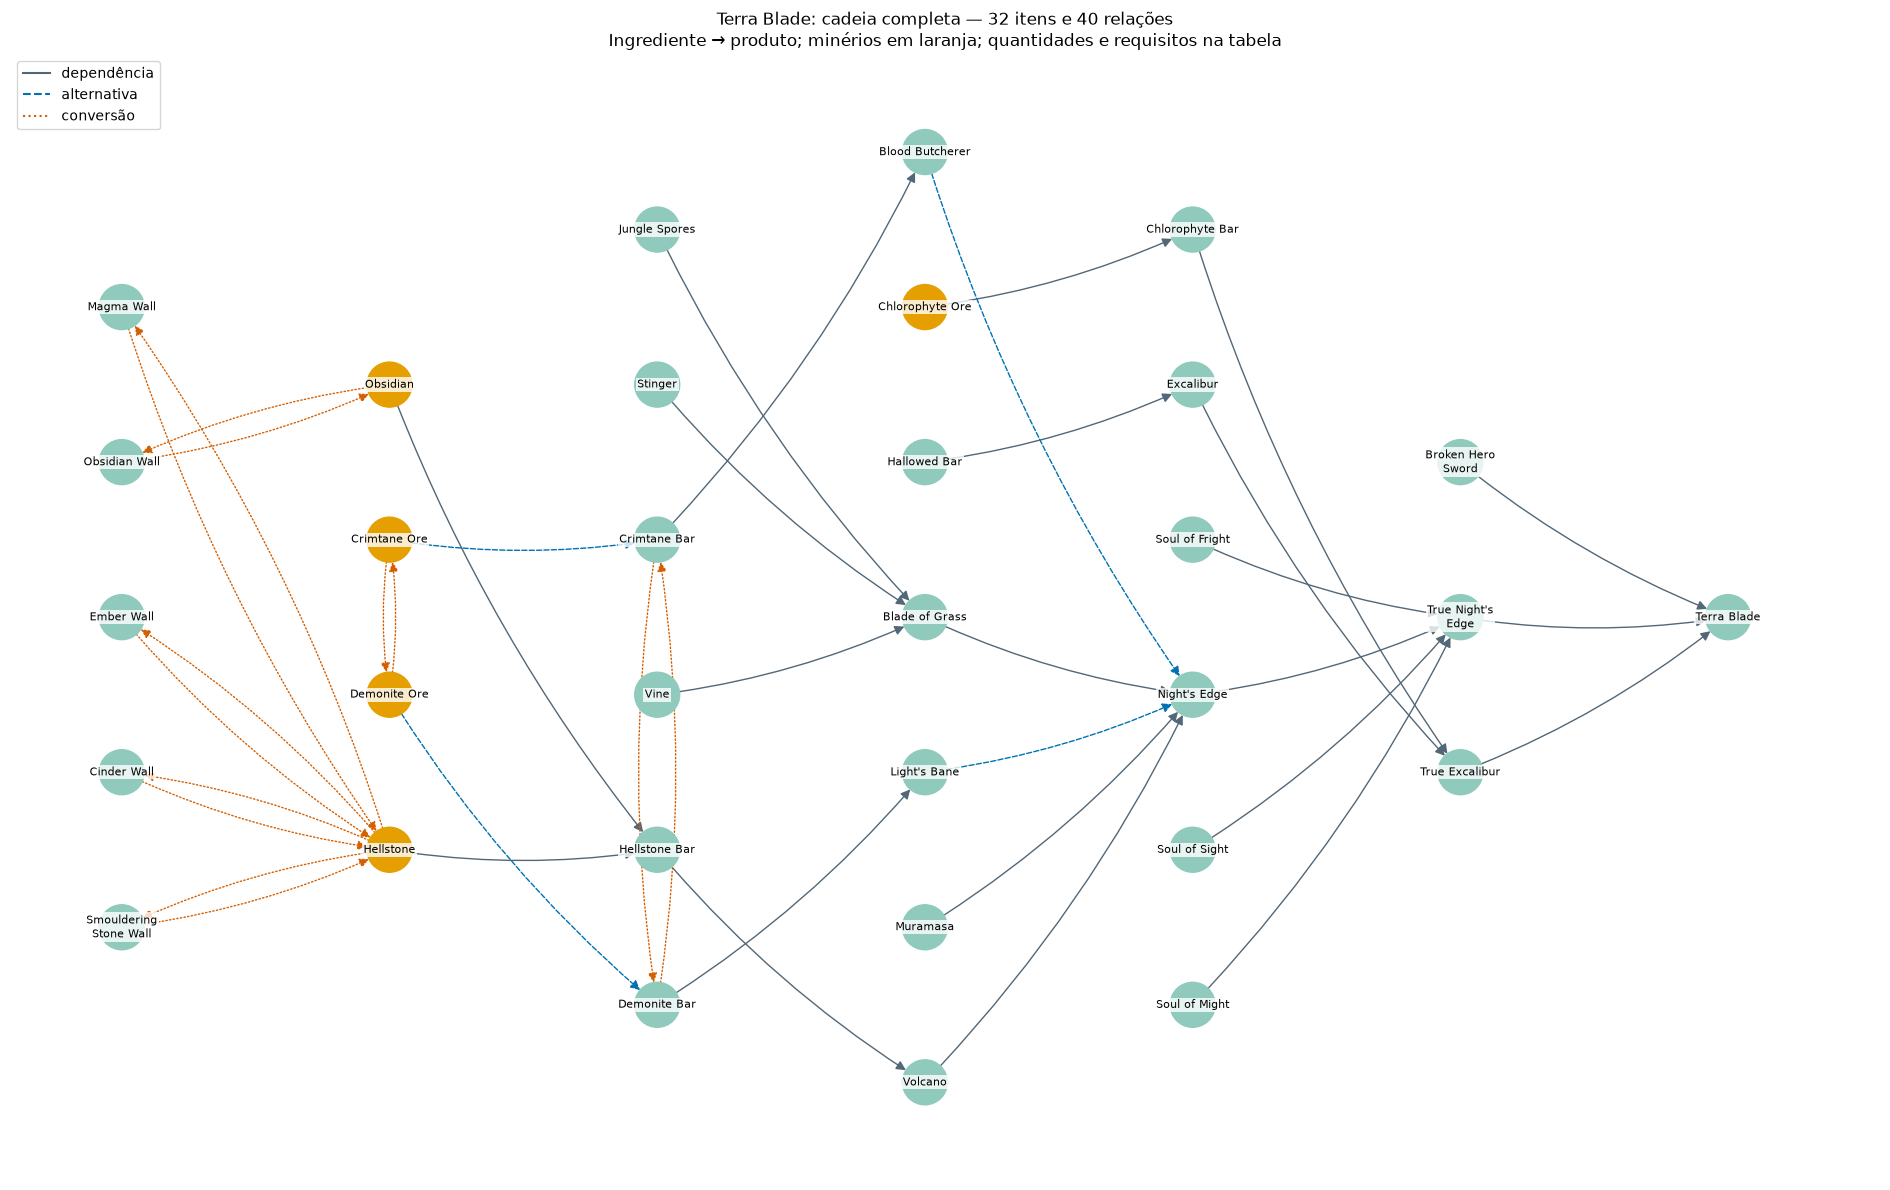

,receita,produto,ingredientes AND,rendimento,estações AND
0,189,Crimtane Ore,1 × (Demonite Ore),1,Chlorophyte Extractinator
1,190,Demonite Ore,1 × (Crimtane Ore),1,Chlorophyte Extractinator
2,205,Crimtane Bar,1 × (Demonite Bar),1,Chlorophyte Extractinator
3,206,Demonite Bar,1 × (Crimtane Bar),1,Chlorophyte Extractinator
4,236,Chlorophyte Bar,5 × (Chlorophyte Ore),1,Adamantite Forge
5,241,Night's Edge,1 × (Blade of Grass) + 1 × (Light's Bane) + 1 × (Muramasa) + 1 × (Volcano),1,Demon Altar
6,242,Night's Edge,1 × (Blade of Grass) + 1 × (Blood Butcherer) + 1 × (Muramasa) + 1 × (Volcano),1,Demon Altar
7,336,Hellstone Bar,3 × (Hellstone) + 1 × (Obsidian),1,Hellforge
8,1980,Demonite Bar,3 × (Demonite Ore),1,Furnace
9,1981,Crimtane Bar,3 × (Crimtane Ore),1,Furnace


In [10]:
levels = dict(nx.single_source_shortest_path_length(G.reverse(copy=False), "TerraBlade"))
crafting_chain = G.subgraph(sorted(levels)).copy()
nx.set_node_attributes(crafting_chain, {k: -d for k, d in levels.items()}, "layer")
assert set(crafting_chain) == nx.ancestors(G, "TerraBlade") | {"TerraBlade"}
for key in ("DemoniteOre", "CrimtaneOre", "ChlorophyteOre", "Hellstone", "Obsidian"):
    assert nx.has_path(crafting_chain, key, "TerraBlade")
chain_rows = []
product_recipes = defaultdict(set)
for rid, r in recipes_desktop.items():
    product_recipes[r["result"]].add(rid)
    if r["result"] in crafting_chain:
        slots = [str(s["amount"]) + " × (" + " OU ".join(items_by_key[k]["name"] for k in s["options"]) + ")"
                 for s in r["resolved_ingredients"]]
        chain_rows.append({"receita": rid, "produto": items_by_key[r["result"]]["name"],
                           "ingredientes AND": " + ".join(slots), "rendimento": r["amount"],
                           "estações AND": ", ".join(r["stations"])})
styles = {"dependência": ("#526777", "solid"), "alternativa": ("#0072B2", "dashed"), "conversão": ("#D55E00", "dotted")}
edge_styles = {}
for u, v, data in crafting_chain.edges(data=True):
    alternative = any(s["group"] for s in data["uses"]) or set(data["recipe_ids"]) != product_recipes[v]
    edge_styles[u, v] = "conversão" if crafting_chain.has_edge(v, u) else "alternativa" if alternative else "dependência"
fig, ax = plt.subplots(figsize=(19, 12))
pos = nx.multipartite_layout(crafting_chain, subset_key="layer")
colors = ["#E69F00" if "ore" in G.nodes[k]["subcategories"] else "#8FCABD" for k in crafting_chain]
nx.draw_networkx_nodes(crafting_chain, pos, node_color=colors, node_size=1050, ax=ax)
for style, (color, line) in styles.items():
    nx.draw_networkx_edges(crafting_chain, pos, edgelist=[e for e, kind in edge_styles.items() if kind == style],
                           edge_color=color, style=line, connectionstyle="arc3,rad=0.08",
                           node_size=1050, arrowsize=14, ax=ax)
nx.draw_networkx_labels(crafting_chain, pos, labels={k: fill(G.nodes[k]["name"], 15) for k in crafting_chain},
                        font_size=8, bbox={"facecolor": "white", "alpha": .8, "edgecolor": "none", "pad": 1}, ax=ax)
ax.legend(handles=[Line2D([0], [0], color=c, linestyle=s, label=k) for k, (c, s) in styles.items()], loc="upper left")
ax.set_title(f"Terra Blade: cadeia completa — {len(crafting_chain)} itens e {crafting_chain.number_of_edges()} relações\n"
             "Ingrediente → produto; minérios em laranja; quantidades e requisitos na tabela")
ax.axis("off")
plt.tight_layout()
plt.show()
with pd.option_context("display.max_rows", None, "display.max_colwidth", 110):
    display(pd.DataFrame(chain_rows))

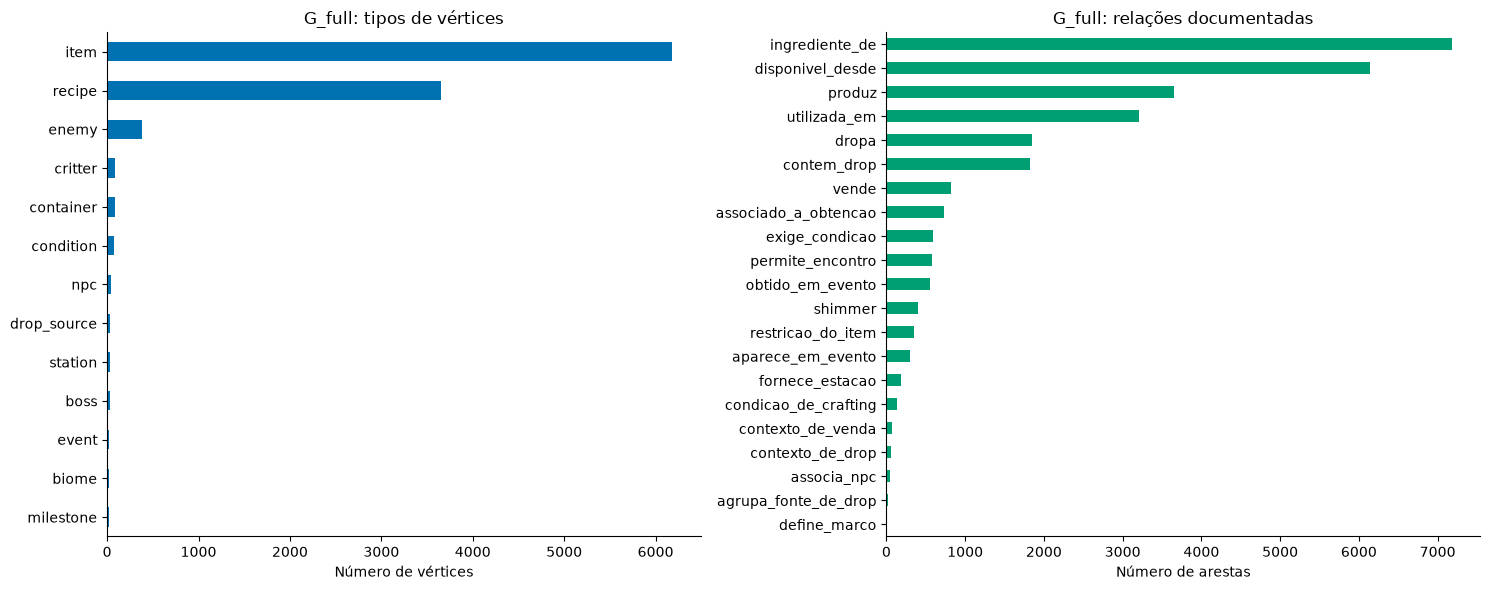

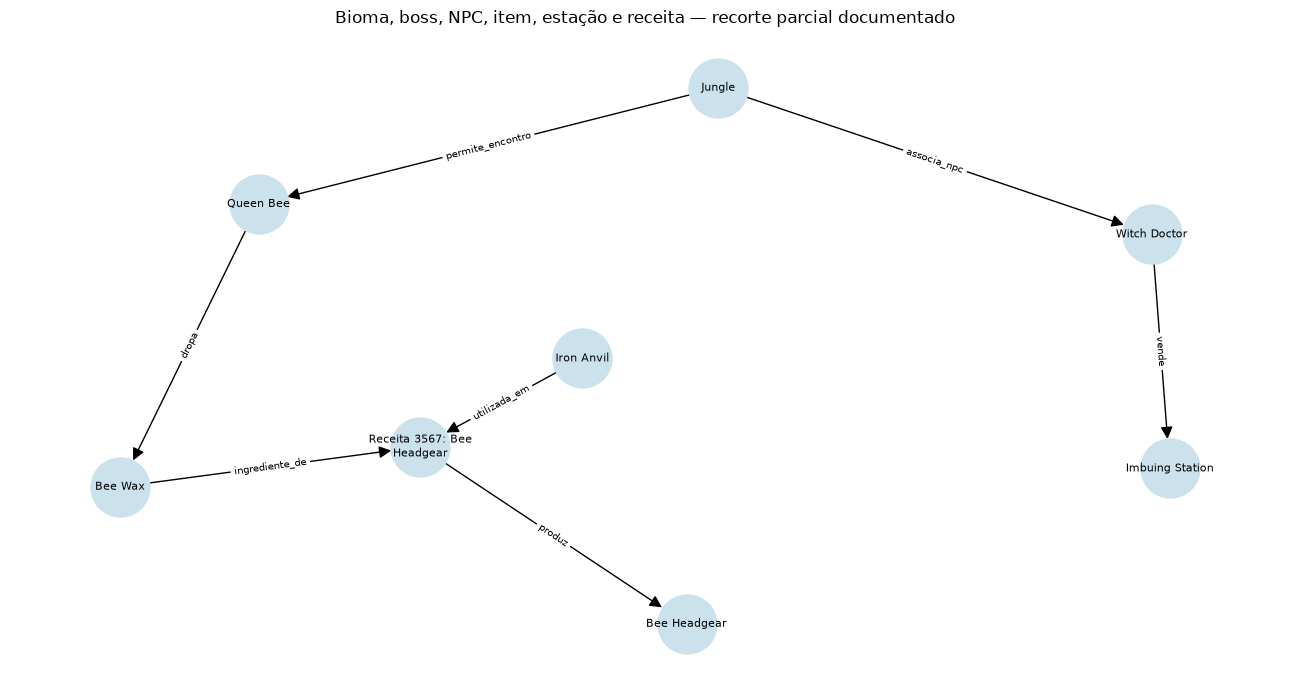

,origem,relação,destino,fonte
0,Queen Bee,dropa,Bee Wax,drops.json/items/BeeWax/0
1,Iron Anvil,utilizada_em,Receita 3567: Bee Headgear,recipes.json/recipes/3567
2,Bee Wax,ingrediente_de,Receita 3567: Bee Headgear,recipes.json/recipes/3567
3,Receita 3567: Bee Headgear,produz,Bee Headgear,recipes.json/recipes/3567
4,Witch Doctor,vende,Imbuing Station,shops.json/ImbuingStation/0
5,Jungle,permite_encontro,Queen Bee,bestiary.json/entries/QueenBee/biomes
6,Jungle,associa_npc,Witch Doctor,bestiary.json/entries/WitchDoctor/biomes


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
node_counts.sort_values().plot.barh(ax=axes[0], color="#0072B2")
relation_counts.sort_values().plot.barh(ax=axes[1], color="#009E73")
for ax, title, xlabel in zip(axes, ["G_full: tipos de vértices", "G_full: relações documentadas"],
                             ["Número de vértices", "Número de arestas"]):
    ax.set(title=title, xlabel=xlabel)
plt.tight_layout()
plt.show()

example_edges = []
for u, v, key, d in G_full.edges(keys=True, data=True):
    if ((u == "biome:jungle" and v in {"boss:queen-bee", "npc:witch-doctor"})
        or (u == "boss:queen-bee" and v == "item:BeeWax")
        or (u == "npc:witch-doctor" and v == "item:ImbuingStation")):
        example_edges.append((u, v, key))
bee_recipe = next(rid for rid, r in recipes_desktop.items()
                  if "armor" in items_by_key[r["result"]]["categories"]
                  and any(s.get("item") == "BeeWax" for s in r["ingredients"]))
for u, v, key, d in G_full.edges(keys=True, data=True):
    if (v == f"recipe:{bee_recipe}" and (u == "item:BeeWax" or d["relation"] == "utilizada_em")) or u == f"recipe:{bee_recipe}":
        example_edges.append((u, v, key))
example = G_full.edge_subgraph(example_edges).copy()
example_simple = nx.DiGraph(example)
pos = nx.spring_layout(example_simple, seed=SEED, k=1.5, iterations=100)
fig, ax = plt.subplots(figsize=(13, 7))
nx.draw_networkx(example_simple, pos, labels={n: fill(G_full.nodes[n]["name"], 18) for n in example},
                 node_size=1800, node_color="#CBE2EC", font_size=8, arrowsize=18, ax=ax)
nx.draw_networkx_edge_labels(example_simple, pos,
                             edge_labels={(u,v): d["relation"] for u,v,d in example_simple.edges(data=True)},
                             font_size=7, ax=ax)
ax.set_title("Bioma, boss, NPC, item, estação e receita — recorte parcial documentado")
ax.axis("off")
plt.tight_layout()
plt.show()
display(pd.DataFrame([{"origem": G_full.nodes[u]["name"], "relação": d["relation"],
                       "destino": G_full.nodes[v]["name"], "fonte": d["source"]}
                      for u, v, d in example.edges(data=True)]))

## 8. Métricas estruturais e escolha do grafo principal
A projeção acadêmica **`H`** conecta dois itens quando um pode ser ingrediente do outro.
Ela é reconstruída por Item → Receita → Item de `G_full` e conferida contra `G`.
Remove direção, paralelismo e laços. Preserva dependências possíveis entre itens; perde a lógica AND/OR,
quantidades, estações, condições e entidades externas ao crafting.

Escolhemos essa projeção homogênea porque permite comparar mecanismos de ligação entre itens
com modelos simples. A projeção integral **`H_full`** também é apresentada, mas mistura hubs de
catálogo, receitas e criaturas. Seus números não entram nas comparações de `H`.

Em grafos desconexos, distância média e diâmetro globais não são finitos. Medimos distâncias na
**maior componente conexa (LCC)**. A média usa BFS a partir de origens amostradas uniformemente.
O erro padrão mede a incerteza dessa amostra de origens. O maior caminho observado é um limite inferior
do diâmetro; duas vezes a menor excentricidade amostrada é um limite superior.
Não chamamos uma estimativa de diâmetro exato.
Densidade, grau, componentes, clustering e assortatividade são exatos nesta representação.

In [12]:
H = nx.Graph(D_craft)
H.remove_edges_from(nx.selfloop_edges(H))
nx.set_node_attributes(H, {n: {"name": G_full.nodes[n]["name"], "type": "item"} for n in H})
H_full = nx.Graph(G_full)
H_full.remove_edges_from(nx.selfloop_edges(H_full))
assert {frozenset(e) for e in H.edges} == {frozenset((f"item:{u}", f"item:{v}")) for u, v in G.edges if u != v}

def sampled_paths(graph, sample_size=PATH_SAMPLES, seed=SEED):
    """BFS: distâncias e eficiência; inalcançáveis contribuem zero para eficiência."""
    nodes = list(graph)
    origins = random.Random(seed).sample(nodes, min(sample_size, len(nodes)))
    means, efficiencies, eccentricities = [], [], []
    for origin in origins:
        distances = nx.single_source_shortest_path_length(graph, origin)
        positive = [d for d in distances.values() if d > 0]
        means.append(np.mean(positive) if positive else 0.0)
        efficiencies.append(sum(1 / d for d in positive) / max(len(graph) - 1, 1))
        eccentricities.append(max(distances.values()))
    return {"distance": float(np.mean(means)),
            "distance_se": float(np.std(means, ddof=1) / np.sqrt(len(means))) if len(means) > 1 else 0.,
            "efficiency": float(np.mean(efficiencies)),
            "diameter_lower": max(eccentricities), "diameter_upper": 2 * min(eccentricities),
            "origins": len(origins)}

def structural_metrics(graph, seed=SEED):
    components = sorted(nx.connected_components(graph), key=len, reverse=True)
    largest = graph.subgraph(components[0]).copy()
    paths = sampled_paths(largest, seed=seed)
    return {"n": len(graph), "m": graph.number_of_edges(), "density": nx.density(graph),
            "mean_degree": 2 * graph.number_of_edges() / len(graph),
            "components": len(components), "isolates": nx.number_of_isolates(graph),
            "lcc_fraction": len(largest) / len(graph), "clustering": nx.average_clustering(graph),
            "assortativity": nx.degree_assortativity_coefficient(graph),
            "distance_lcc": paths["distance"], "distance_se": paths["distance_se"],
            "diameter_lower": paths["diameter_lower"], "diameter_upper": paths["diameter_upper"],
            "efficiency": sampled_paths(graph, seed=seed)["efficiency"]}

real_metrics = structural_metrics(H)
full_metrics = structural_metrics(H_full)
display(pd.DataFrame([real_metrics, full_metrics], index=["H: crafting (principal)", "H_full: todas as relações"]).T)
components_H = sorted(nx.connected_components(H), key=len, reverse=True)
LCC = H.subgraph(components_H[0]).copy()
degrees = pd.Series(dict(H.degree()), name="grau")
clustering = pd.Series(nx.clustering(H), name="clustering")
display(Markdown(f"A maior componente de H contém **{len(LCC):,}/{len(H):,} itens** "
                 f"({real_metrics['lcc_fraction']:.1%}). Sua distância média estimada é "
                 f"**{real_metrics['distance_lcc']:.2f} ± {real_metrics['distance_se']:.2f}** (erro padrão); "
                 f"diâmetro entre **{real_metrics['diameter_lower']} e {real_metrics['diameter_upper']}**. "
                 "Cada passo é uma dependência possível, sem significado de tempo ou custo."))

,H: crafting (principal),H_full: todas as relações
n,3773.000000,10672.000000
m,6692.000000,28150.000000
density,0.000940,0.000494
mean_degree,3.547310,5.275487
components,62.000000,85.000000
isolates,0.000000,83.000000
lcc_fraction,0.953883,0.991942
clustering,0.032264,0.064757
assortativity,-0.222817,-0.115023
distance_lcc,5.657095,3.706489


A maior componente de H contém **3,599/3,773 itens** (95.4%). Sua distância média estimada é **5.66 ± 0.14** (erro padrão); diâmetro entre **21 e 24**. Cada passo é uma dependência possível, sem significado de tempo ou custo.

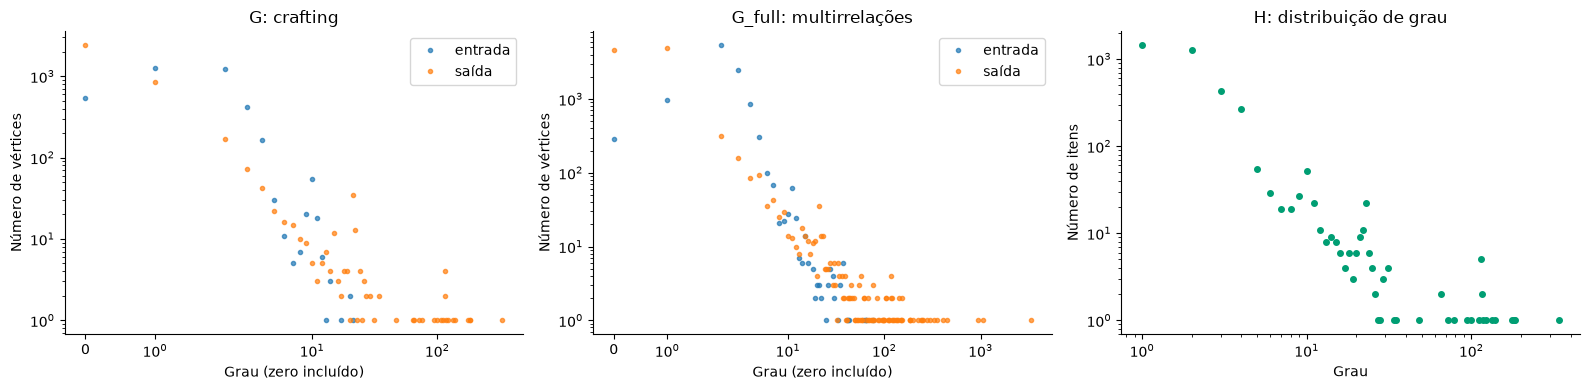

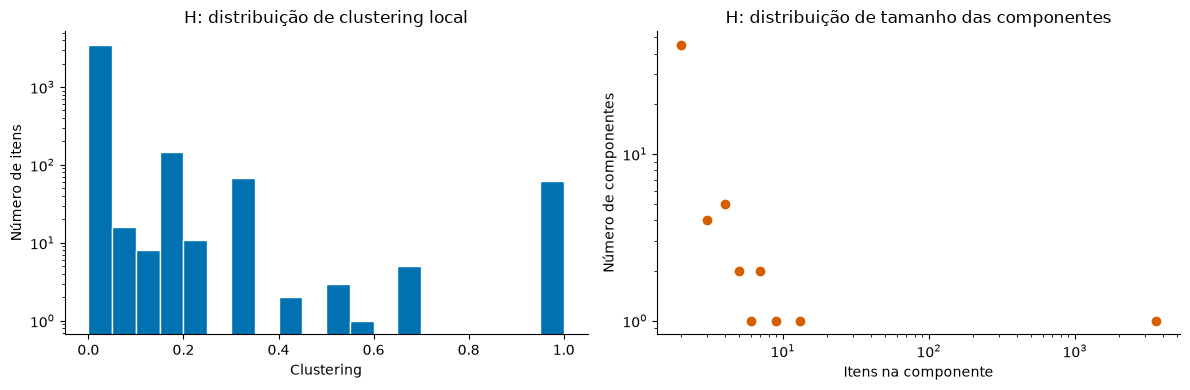

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, graph, title in [(axes[0], G, "G: crafting"), (axes[1], G_full, "G_full: multirrelações")]:
    for label, degree_view in [("entrada", graph.in_degree()), ("saída", graph.out_degree())]:
        counts = pd.Series(Counter(dict(degree_view).values())).sort_index()
        ax.plot(counts.index, counts.values, "o", markersize=3, label=label, alpha=.7)
    ax.set(xscale="symlog", yscale="log", xlabel="Grau (zero incluído)", ylabel="Número de vértices", title=title)
    ax.legend()
counts = degrees.value_counts().sort_index()
axes[2].loglog(counts.index, counts.values, "o", markersize=4, color="#009E73")
axes[2].set(title="H: distribuição de grau", xlabel="Grau", ylabel="Número de itens")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(clustering.values, bins=np.linspace(0, 1, 21), color="#0072B2", edgecolor="white")
axes[0].set(title="H: distribuição de clustering local", xlabel="Clustering", ylabel="Número de itens", yscale="log")
sizes = pd.Series(Counter(map(len, components_H))).sort_index()
axes[1].loglog(sizes.index, sizes.values, "o", color="#D55E00")
axes[1].set(title="H: distribuição de tamanho das componentes", xlabel="Itens na componente", ylabel="Número de componentes")
plt.tight_layout()
plt.show()

## 9. Centralidades e comunidades
Todas as quatro centralidades principais usam **H**, sem pesos:

- Degree: fração dos itens diretamente relacionados.
- Betweenness: fração dos menores caminhos que passam pelo item; aproximada com origens amostradas.
- Closeness: inverso da distância aos alcançáveis, com correção de Wasserman–Faust para componentes.
- PageRank: passeio aleatório com teletransporte (α=0,85). Em H, tende a acompanhar o grau.

São medidas estruturais, não poder de combate ou indispensabilidade de crafting.
Betweenness exata seria mais cara: fixamos `k=BETWEENNESS_SAMPLES`; closeness é calculada
exatamente nesta projeção moderada. Os três destaques usam a média dos **ranks percentuais**
das quatro medidas (mesmo peso), um critério declarado que combina alcance, intermediação e vizinhança.
A correlação grau–PageRank limita a independência desse consenso; mostramos também rankings separados.

Referências: [betweenness](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.centrality.betweenness_centrality.html),
[closeness](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.centrality.closeness_centrality.html).

Na execução analisada, **Torch** conecta famílias de iluminação; **Stone Block** é material
para blocos e construção; **Iron Bar** atende receitas de ferramentas e mobiliário.
A possibilidade de substituir Iron Bar por Lead Bar em grupos `Any Iron Bar` é um exemplo
de por que centralidade não implica obrigatoriedade. Posições próximas no ranking combinado
devem ser interpretadas com cuidado, pois betweenness é amostrada.


,métrica,id,nome,valor
0,degree,item:Torch,Torch,0.090403
1,degree,item:IronBar,Iron Bar,0.048515
2,degree,item:LeadBar,Lead Bar,0.048250
3,degree,item:Silk,Silk,0.046925
4,degree,item:StoneBlock,Stone Block,0.037116
5,betweenness,item:Torch,Torch,0.197152
6,betweenness,item:StoneBlock,Stone Block,0.135088
7,betweenness,item:Glass,Glass,0.131716
8,betweenness,item:Silk,Silk,0.100684
9,betweenness,item:LeadBar,Lead Bar,0.071258


,nome,tipo,degree,betweenness,closeness,pagerank,consenso
item:Torch,Torch,item,0.090403,0.197152,0.275931,0.020587,1.000000
item:StoneBlock,Stone Block,item,0.037116,0.135088,0.254337,0.010990,0.999271
item:IronBar,Iron Bar,item,0.048515,0.069873,0.257602,0.009193,0.999271


**Torch (item:Torch, item):** participa como ingrediente possível em **349 receitas**, tem **341 vizinhos** e intermediação **0.19715**. Categorias da fonte: material-furniture, torch-campfire. Exemplos de produtos: Lesion Lantern, Lesion Candle, Lesion Lamp, Lesion Candelabra. Sua função como material em várias receitas ajuda a explicar a centralidade; opções de grupos não o tornam obrigatório em todas elas.

**Stone Block (item:StoneBlock, item):** participa como ingrediente possível em **140 receitas**, tem **140 vizinhos** e intermediação **0.13509**. Categorias da fonte: material-block, other-block. Exemplos de produtos: Asphalt Block, Crystal Block, Sunplate Block, Gothic Brick. Sua função como material em várias receitas ajuda a explicar a centralidade; opções de grupos não o tornam obrigatório em todas elas.

**Iron Bar (item:IronBar, item):** participa como ingrediente possível em **186 receitas**, tem **183 vizinhos** e intermediação **0.06987**. Categorias da fonte: bar. Exemplos de produtos: Lesion Chest, Lesion Clock, Steampunk Chest, Steampunk Clock. Sua função como material em várias receitas ajuda a explicar a centralidade; opções de grupos não o tornam obrigatório em todas elas.

**Diferenças entre rankings:** degree: Torch; betweenness: Torch; closeness: Torch; pagerank: Torch. Grau privilegia ligações diretas; betweenness identifica intermediação; closeness, acesso às regiões conectadas; PageRank, vizinhanças visitadas com frequência. Nenhum ranking mede poder de combate.

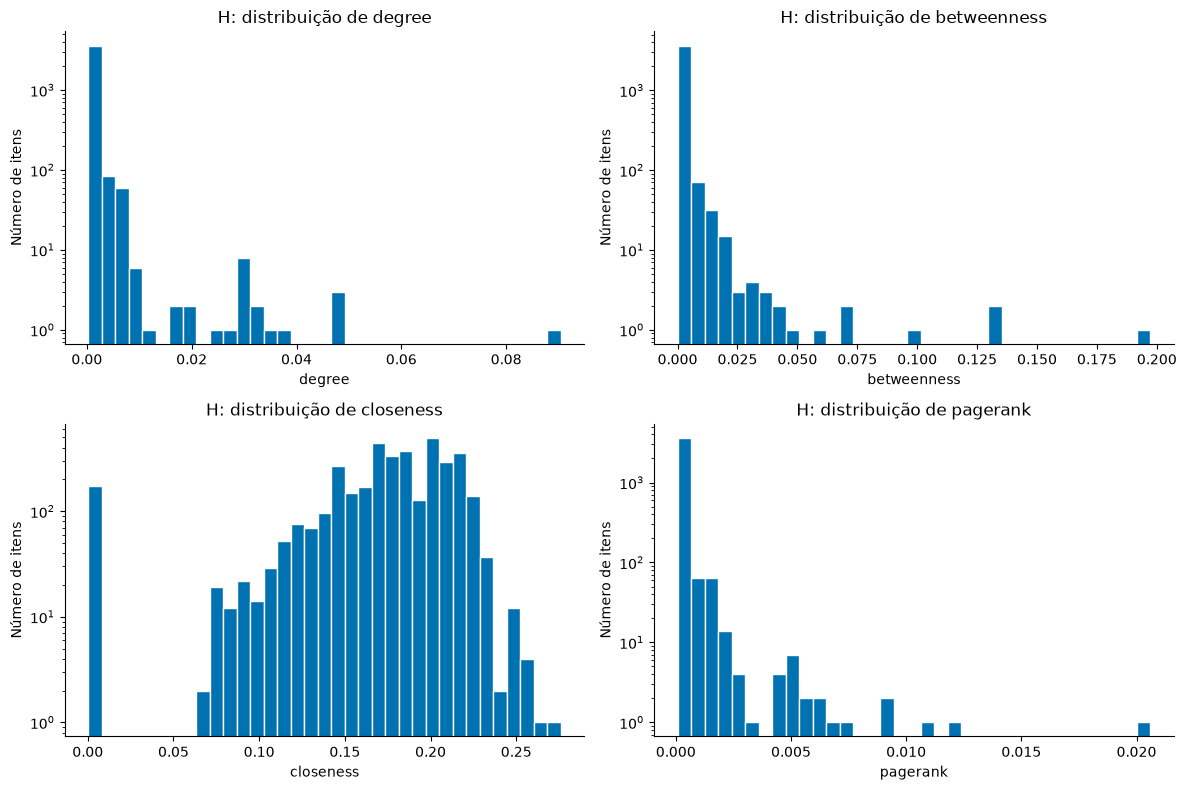

In [14]:
centralities = pd.DataFrame({
    "degree": nx.degree_centrality(H),
    "betweenness": nx.betweenness_centrality(H, k=min(BETWEENNESS_SAMPLES, len(H)), seed=SEED, weight=None),
    "closeness": nx.closeness_centrality(H, wf_improved=True),
    "pagerank": nx.pagerank(H, alpha=.85, weight=None, tol=1e-10, max_iter=200),
})
metric_columns = list(centralities.columns)
centralities["consenso"] = centralities[metric_columns].rank(pct=True).mean(axis=1)
centralities["nome"] = [H.nodes[n]["name"] for n in centralities.index]
centralities["tipo"] = "item"
rankings = []
for metric in metric_columns:
    for node, row in centralities.nlargest(5, metric).iterrows():
        rankings.append({"métrica": metric, "id": node, "nome": row["nome"], "valor": row[metric]})
display(pd.DataFrame(rankings))
top3 = centralities.sort_values(["consenso", "betweenness"], ascending=False).head(3)
display(top3[["nome", "tipo", *metric_columns, "consenso"]])
for node, row in top3.iterrows():
    key = node.removeprefix("item:")
    uses = [r for r in recipes_desktop.values()
            if any(key in slot["options"] for slot in r["resolved_ingredients"])]
    products = list(dict.fromkeys(items_by_key[r["result"]]["name"] for r in uses))[:4]
    display(Markdown(f"**{row['nome']} ({node}, item):** participa como ingrediente possível em "
                     f"**{len(uses)} receitas**, tem **{H.degree(node)} vizinhos** e intermediação "
                     f"**{row['betweenness']:.5f}**. Categorias da fonte: "
                     f"{', '.join(items_by_key[key]['subcategories'])}. Exemplos de produtos: "
                     f"{', '.join(products)}. Sua função como material em várias receitas ajuda a "
                     "explicar a centralidade; opções de grupos não o tornam obrigatório em todas elas."))
leaders = {m: centralities[m].idxmax() for m in metric_columns}
display(Markdown("**Diferenças entre rankings:** " + "; ".join(
    f"{m}: {H.nodes[n]['name']}" for m, n in leaders.items()) +
    ". Grau privilegia ligações diretas; betweenness identifica intermediação; closeness, acesso "
    "às regiões conectadas; PageRank, vizinhanças visitadas com frequência. Nenhum ranking mede poder de combate."))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, metric in zip(axes.flat, metric_columns):
    ax.hist(centralities[metric], bins=35, color="#0072B2", edgecolor="white")
    ax.set(title=f"H: distribuição de {metric}", xlabel=metric, ylabel="Número de itens", yscale="log")
plt.tight_layout()
plt.show()

Louvain encontra comunidades em H por maximização heurística da modularidade.
Fixamos semente e resolução 1.0; modularidade alta indica separação topológica, não uma partição
verdadeira ou única do jogo. Examinamos categorias, milestones e associações de bioma registradas.
Um item pode ter várias categorias; essas contagens não precisam somar o tamanho da comunidade.
Ausência de bioma no catálogo não prova ausência de ligação temática.

,comunidade,itens,hubs,categorias,biomas informados,milestones
0,0,424,"Wood, Rich Mahogany, Boreal Wood","[(furniture, 232), (crafting-material, 95), (light-source, 60)]","[(crimson, 2), (snow, 2)]","[(start, 342), (wall-of-flesh, 51)]"
1,1,381,"Torch, Chain, Water Bucket","[(furniture, 337), (light-source, 127), (crafting-station, 58)]","[(underground, 3), (jungle, 2)]","[(start, 213), (lunatic-cultist, 80)]"
2,2,354,"Stone Block, Terrarium, Mythril Bar","[(crafting-material, 164), (furniture, 140), (block, 40)]","[(underground, 11), (forest-surface, 7)]","[(start, 267), (wall-of-flesh, 58)]"
3,3,284,"Iron Bar, Lead Bar, Glass","[(furniture, 245), (storage, 150), (crafting-material, 110)]",[],"[(start, 142), (skeletron, 80)]"
4,4,180,"Hallowed Bar, Adamantite Bar, Forbidden Block","[(crafting-material, 58), (weapon, 54), (furniture, 45)]","[(corruption, 4), (crimson, 4)]","[(wall-of-flesh, 90), (any-mech, 60)]"
5,5,178,"Crimtane Brick, Demonite Brick, Flesh Block","[(furniture, 74), (crafting-material, 59), (wall, 23)]","[(jungle, 2), (glowing-mushroom, 1)]","[(start, 93), (evil-boss, 36)]"
6,6,169,"Meteorite Brick, Meteorite Bar, Crystal Shard","[(crafting-material, 70), (wall, 30), (weapon, 27)]","[(meteorite, 1)]","[(start, 132), (evil-boss, 19)]"
7,7,154,"Book, Bone, Librarian Block","[(furniture, 123), (crafting-material, 21), (light-source, 16)]","[(dungeon, 1), (jungle, 1)]","[(skeletron, 102), (wall-of-flesh, 31)]"
8,8,148,"Feywood, Glowing Mushroom, Office Block","[(furniture, 59), (crafting-material, 40), (weapon, 26)]","[(underground, 4), (forest-surface, 3)]","[(start, 104), (wall-of-flesh, 30)]"
9,9,146,"Bottled Water, Daybloom, Seafood Dinner","[(crafting-material, 62), (potion, 54), (furniture, 17)]","[(forest-surface, 9), (underground, 8)]","[(start, 98), (wall-of-flesh, 21)]"


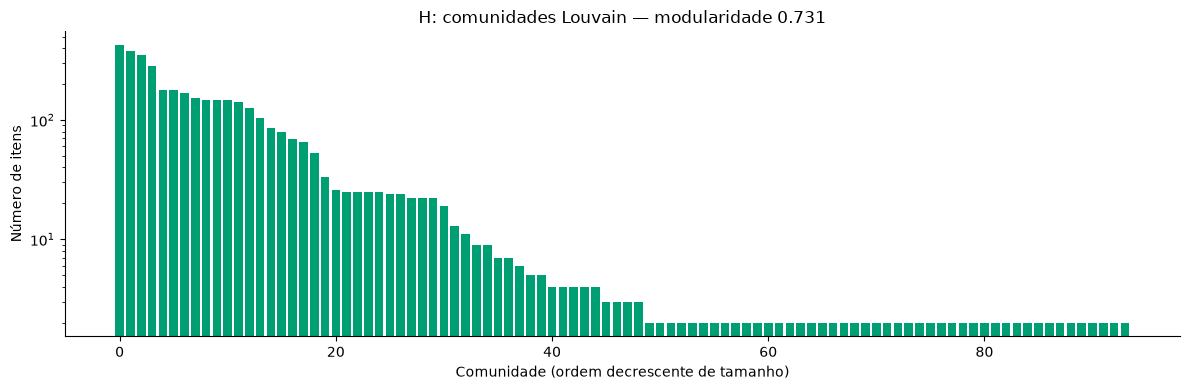

Foram encontradas **94 comunidades**, com modularidade **0.731**. A maior contém **424 itens**; seus hubs são **Wood, Rich Mahogany, Boreal Wood**. As categorias mais frequentes são [('furniture', 232), ('crafting-material', 95), ('light-source', 60)]. Esses dados caracterizam agrupamentos de crafting; os biomas listados são associações parciais de obtenção, não nomes automáticos de comunidades.

In [15]:
communities = sorted(nx.community.louvain_communities(H, seed=SEED, weight=None, resolution=1.0),
                     key=lambda c: (-len(c), min(c)))
modularity = nx.community.modularity(H, communities, weight=None)
community_rows = []
for index, members in enumerate(communities):
    keys = [n.removeprefix("item:") for n in sorted(members)]
    categories_count = Counter(c for k in keys for c in items_by_key[k]["categories"])
    biomes_count = Counter(b for k in keys for b in items_by_key[k]["biomes"])
    milestones_count = Counter(items_by_key[k].get("milestone", "não informado") for k in keys)
    hubs = sorted(members, key=lambda n: (-H.degree(n), n))[:3]
    community_rows.append({"comunidade": index, "itens": len(members),
                           "hubs": ", ".join(H.nodes[n]["name"] for n in hubs),
                           "categorias": categories_count.most_common(3),
                           "biomas informados": biomes_count.most_common(2),
                           "milestones": milestones_count.most_common(2)})
community_table = pd.DataFrame(community_rows)
display(community_table.head(12))
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(range(len(communities)), [len(c) for c in communities], color="#009E73")
ax.set(title=f"H: comunidades Louvain — modularidade {modularity:.3f}",
       xlabel="Comunidade (ordem decrescente de tamanho)", ylabel="Número de itens", yscale="log")
plt.tight_layout()
plt.show()
display(Markdown(f"Foram encontradas **{len(communities)} comunidades**, com modularidade "
                 f"**{modularity:.3f}**. A maior contém **{len(communities[0])} itens**; seus hubs são "
                 f"**{community_rows[0]['hubs']}**. As categorias mais frequentes são "
                 f"{community_rows[0]['categorias']}. Esses dados caracterizam agrupamentos de crafting; "
                 "os biomas listados são associações parciais de obtenção, não nomes automáticos de comunidades."))

## 10. Comparação com redes sintéticas
Usamos **os mesmos n vértices de H**, grafos simples, não dirigidos e sem pesos.

- **Erdős–Rényi G(n,m):** exatamente o mesmo número de arestas; densidade idêntica.
- **Watts–Strogatz:** vizinhança inicial de grau par mais próximo do grau médio real; rewiring β=0,1.
- **Barabási–Albert:** número inteiro de ligações por novo nó mais próximo de ⟨k⟩/2.
- **Nulo de graus:** trocas duplas de arestas de H preservando exatamente o grau de cada nó.

WS e BA têm restrições inteiras, por isso suas densidades diferem um pouco; a tabela mostra os valores.
O nulo usa 5m trocas aceitas: não afirmamos mistura uniforme nem preservação das componentes.
Cada modelo tem cinco realizações independentes com sementes fixas. Média e desvio padrão são
**entre realizações**; o erro das distâncias por amostragem é separado.
Todas as distâncias são medidas na LCC e acompanhadas de sua fração de vértices.
Nós sintéticos não possuem tipos Terraria; a comparação é topológica.

A CCDF P(K≥k) facilita observar a cauda sem ajustar uma reta arbitrária.
Cauda longa não comprova lei de potência nem mecanismo de ligação preferencial.

In [16]:
n, m = len(H), H.number_of_edges()
mean_degree = 2 * m / n
ws_k = max(2, 2 * round(mean_degree / 2))
ba_m = max(1, round(mean_degree / 2))
synthetic_rows, degree_samples = [], defaultdict(list)
for realization in range(N_REALIZATIONS):
    seed = SEED + 100 * (realization + 1)
    null = H.copy()
    nx.double_edge_swap(null, nswap=5 * m, max_tries=100 * m, seed=seed)
    assert dict(null.degree()) == dict(H.degree())
    models = {
        "ER": nx.gnm_random_graph(n, m, seed=seed),
        "WS": nx.watts_strogatz_graph(n, ws_k, .1, seed=seed),
        "BA": nx.barabasi_albert_graph(n, ba_m, seed=seed),
        "Nulo de graus": null,
    }
    for model, graph in models.items():
        assert not graph.is_directed() and not graph.is_multigraph()
        assert len(graph) == n and nx.number_of_selfloops(graph) == 0
        row = structural_metrics(graph, seed=seed)
        synthetic_rows.append({"modelo": model, "realização": realization, **row})
        degree_samples[model].append(np.array([d for _, d in graph.degree()]))
    print(f"Realização {realization + 1}/{N_REALIZATIONS} concluída.")
synthetic = pd.DataFrame(synthetic_rows)
comparison_columns = ["n", "m", "density", "mean_degree", "clustering", "distance_lcc",
                      "distance_se", "assortativity", "components", "isolates", "lcc_fraction", "efficiency"]

print(f"Parâmetros: n={n}; ER m={m}; WS k={ws_k}, beta=0.1; BA m={ba_m}; nulo {5*m} trocas.")
model_means = synthetic.groupby("modelo")[comparison_columns].mean()
model_stds = synthetic.groupby("modelo")[comparison_columns].std()
comparison_table = pd.DataFrame({"H real": {metric: f"{real_metrics[metric]:.5g}" for metric in comparison_columns}})
for model in model_means.index:
    comparison_table[model] = [f"{model_means.loc[model, metric]:.5g} ± {model_stds.loc[model, metric]:.3g}"
                               for metric in comparison_columns]
display(comparison_table)
# As realizações individuais ficam disponíveis em synthetic.


Realização 1/5 concluída.


Realização 2/5 concluída.


Realização 3/5 concluída.


Realização 4/5 concluída.


Realização 5/5 concluída.
Parâmetros: n=3773; ER m=6692; WS k=4, beta=0.1; BA m=2; nulo 33460 trocas.


,H real,BA,ER,Nulo de graus,WS
n,3773,3773 ± 0,3773 ± 0,3773 ± 0,3773 ± 0
m,6692,7542 ± 0,6692 ± 0,6692 ± 0,7546 ± 0
density,0.00094043,0.0010599 ± 0,0.00094043 ± 0,0.00094043 ± 0,0.0010604 ± 0
mean_degree,3.5473,3.9979 ± 0,3.5473 ± 0,3.5473 ± 0,4 ± 0
clustering,0.032264,0.011107 ± 0.00121,0.00087165 ± 0.000356,0.048123 ± 0.00345,0.37342 ± 0.00543
distance_lcc,5.6571,4.6026 ± 0.0626,6.5592 ± 0.078,4.1196 ± 0.0402,10.885 ± 0.17
distance_se,0.13749,0.043294 ± 0.00149,0.052148 ± 0.00561,0.063623 ± 0.0054,0.073668 ± 0.0051
assortativity,-0.22282,-0.059296 ± 0.00527,-0.0038074 ± 0.00528,-0.1293 ± 0.00314,-0.026889 ± 0.0171
components,62,1 ± 0,112.6 ± 5.03,96 ± 13.2,1 ± 0
isolates,0,0 ± 0,104.2 ± 7.79,0 ± 0,0 ± 0


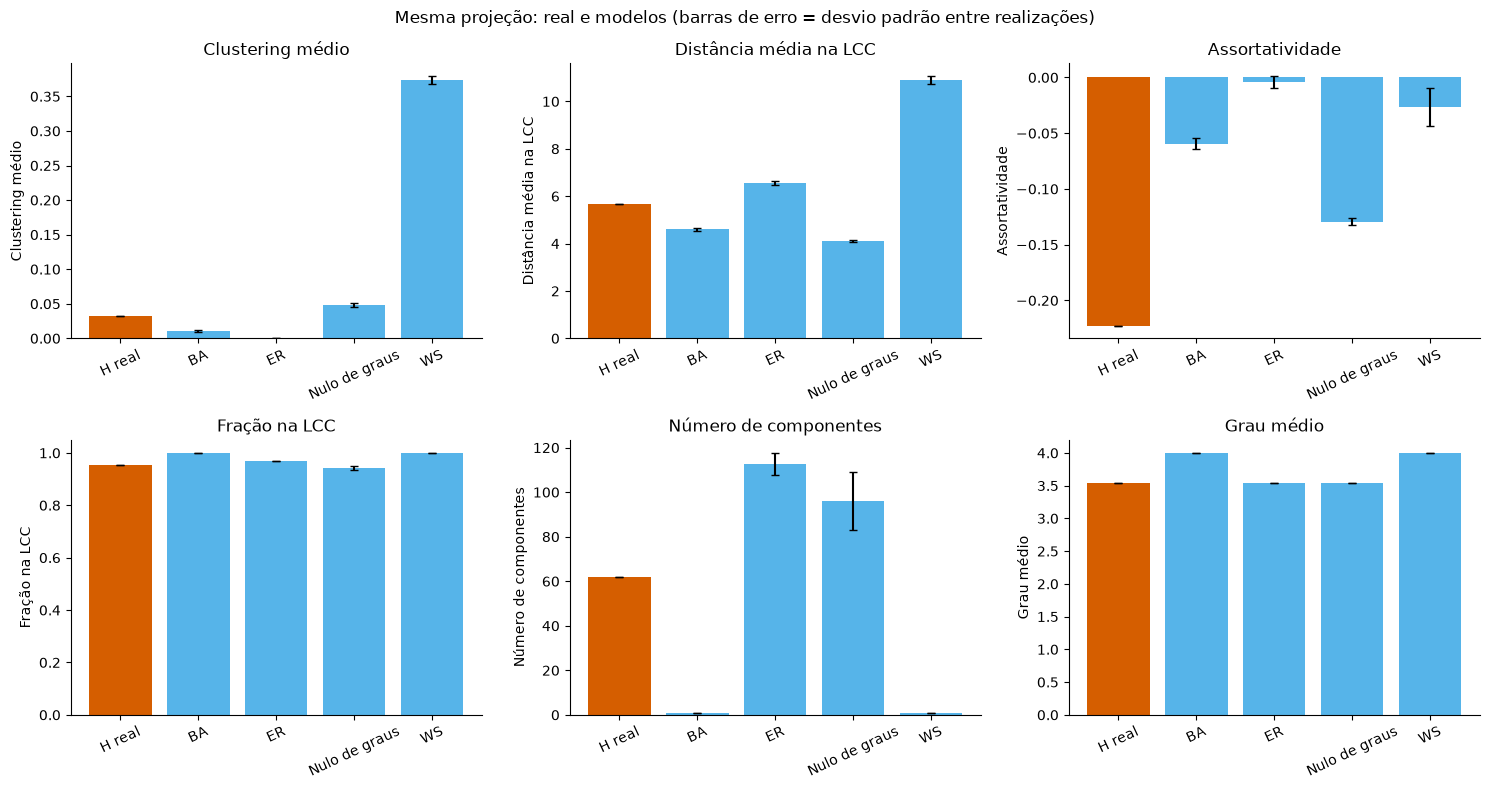

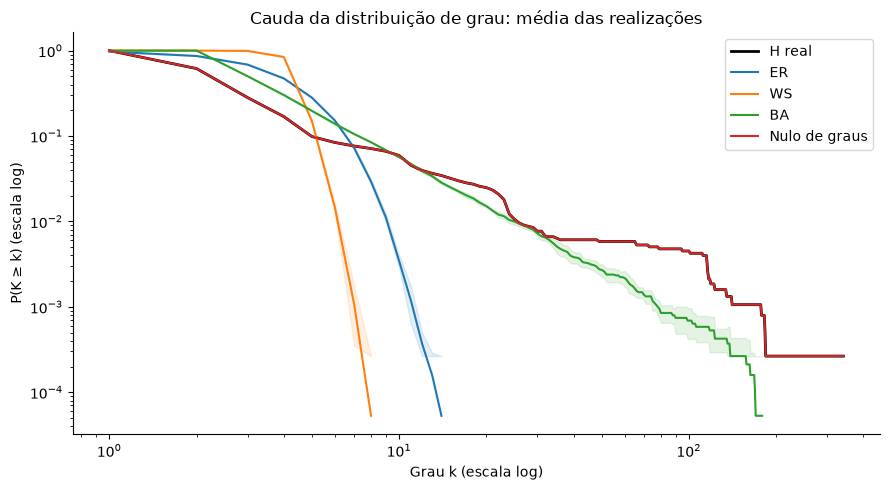

,CV do grau
H real,3.118193
ER,0.534828
WS,0.154256
BA,1.493498
Nulo de graus,3.118193


**Evidências:** clustering real/ER = **37.01**; distância LCC real/ER = **0.86**; razão σ = (C/C_ER)/(L/L_ER) = **42.92**. O coeficiente de variação do grau real é **3.12**, contra **0.53** (ER), **0.15** (WS) e **1.49** (BA). σ é apenas diagnóstico: as LCCs podem ter tamanhos diferentes e o grau real é heterogêneo.

**Controle da sequência de graus:** C/C_nulo = **0.67**, L/L_nulo = **1.37**, σ_nulo = **0.49**. Se o clustering não supera esse controle, o contraste com ER pode ser explicado em parte pelos hubs, sem evidenciar uma organização small-world adicional.

**A qual modelo se aproxima?** H tem traços small-world em relação a ER (clustering maior com caminhos relativamente curtos), mas esse diagnóstico precisa do controle de graus. O nulo de graus não confirma excesso de organização small-world: não há uma classificação inequívoca entre os três modelos. A grande dispersão de graus e os hubs aproximam esse aspecto qualitativo de BA, enquanto ER e WS têm graus muito mais homogêneos. Ainda assim, H não reproduz integralmente nenhum dos três modelos. Não foi comprovada uma lei de potência: isso exigiria ajuste de cauda, corte, teste de aderência e comparação com distribuições alternativas. A conclusão se refere à projeção de crafting, não à dinâmica completa do Terraria.

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
compare_metrics = [("clustering", "Clustering médio"), ("distance_lcc", "Distância média na LCC"),
                   ("assortativity", "Assortatividade"), ("lcc_fraction", "Fração na LCC"),
                   ("components", "Número de componentes"), ("mean_degree", "Grau médio")]
labels = ["H real", *model_means.index]
for ax, (metric, title) in zip(axes.flat, compare_metrics):
    values = [real_metrics[metric], *model_means[metric]]
    errors = [0, *model_stds[metric]]
    ax.bar(labels, values, yerr=errors, capsize=3, color=["#D55E00"] + ["#56B4E9"] * len(model_means))
    ax.set(title=title, ylabel=title)
    ax.tick_params(axis="x", rotation=25)
plt.suptitle("Mesma projeção: real e modelos (barras de erro = desvio padrão entre realizações)")
plt.tight_layout()
plt.show()

def degree_ccdf(values):
    counts = np.bincount(values)
    return np.arange(len(counts)), np.cumsum(counts[::-1])[::-1] / len(values)

fig, ax = plt.subplots(figsize=(9, 5))
x, y = degree_ccdf(degrees.to_numpy())
ax.loglog(x[1:], y[1:], color="black", linewidth=2, label="H real")
for model, samples in degree_samples.items():
    max_degree = max(int(a.max()) for a in samples)
    ccdfs = np.array([np.cumsum(np.bincount(a, minlength=max_degree+1)[::-1])[::-1] / len(a)
                     for a in samples])
    x = np.arange(max_degree+1)
    avg, sd = ccdfs.mean(axis=0), ccdfs.std(axis=0)
    line, = ax.loglog(x[1:], avg[1:], label=model)
    ax.fill_between(x[1:], np.maximum(avg[1:]-sd[1:], 1/n), np.maximum(avg[1:]+sd[1:], 1/n),
                     alpha=.12, color=line.get_color())
ax.set(title="Cauda da distribuição de grau: média das realizações",
       xlabel="Grau k (escala log)", ylabel="P(K ≥ k) (escala log)")
ax.legend()
plt.tight_layout()
plt.show()

cv_real = degrees.std(ddof=0) / degrees.mean()
cv_models = {model: np.mean([a.std() / a.mean() for a in samples]) for model, samples in degree_samples.items()}
gamma = real_metrics["clustering"] / model_means.loc["ER", "clustering"]
lam = real_metrics["distance_lcc"] / model_means.loc["ER", "distance_lcc"]
sigma = gamma / lam
display(pd.DataFrame({"CV do grau": {"H real": cv_real, **cv_models}}))
display(Markdown(f"**Evidências:** clustering real/ER = **{gamma:.2f}**; distância LCC real/ER = "
                 f"**{lam:.2f}**; razão σ = (C/C_ER)/(L/L_ER) = **{sigma:.2f}**. "
                 f"O coeficiente de variação do grau real é **{cv_real:.2f}**, contra "
                 f"**{cv_models['ER']:.2f}** (ER), **{cv_models['WS']:.2f}** (WS) e **{cv_models['BA']:.2f}** (BA). "
                 "σ é apenas diagnóstico: as LCCs podem ter tamanhos diferentes e o grau real é heterogêneo."))

gamma_null = real_metrics["clustering"] / model_means.loc["Nulo de graus", "clustering"]
lambda_null = real_metrics["distance_lcc"] / model_means.loc["Nulo de graus", "distance_lcc"]
sigma_null = gamma_null / lambda_null
display(Markdown(f"**Controle da sequência de graus:** C/C_nulo = **{gamma_null:.2f}**, "
                 f"L/L_nulo = **{lambda_null:.2f}**, σ_nulo = **{sigma_null:.2f}**. "
                 "Se o clustering não supera esse controle, o contraste com ER pode ser explicado "
                 "em parte pelos hubs, sem evidenciar uma organização small-world adicional."))
if gamma > 1 and sigma > 1:
    classification = ("H tem traços small-world em relação a ER (clustering maior com caminhos relativamente curtos), "
                      "mas esse diagnóstico precisa do controle de graus.")
else:
    classification = "O diagnóstico relativo a ER não sustenta traços small-world nesta projeção."
if sigma_null <= 1:
    classification += (" O nulo de graus não confirma excesso de organização small-world: "
                       "não há uma classificação inequívoca entre os três modelos.")
display(Markdown("**A qual modelo se aproxima?** " + classification +
                 " A grande dispersão de graus e os hubs aproximam esse aspecto qualitativo de BA, "
                 "enquanto ER e WS têm graus muito mais homogêneos. Ainda assim, H não reproduz "
                 "integralmente nenhum dos três modelos. Não foi comprovada uma lei de potência: "
                 "isso exigiria ajuste de cauda, corte, teste de aderência e comparação com distribuições alternativas. "
                 "A conclusão se refere à projeção de crafting, não à dinâmica completa do Terraria."))


## 11. Robustez e conectividade
Simulamos falhas de itens em H: remoção aleatória (dez ordens independentes) e remoção direcionada
pelo ranking inicial de betweenness aproximada ou de grau. O ataque é **estático**: o ranking não
é recalculado após cada remoção. Isso mede uma estratégia específica, não o pior ataque possível.

S(q)=|LCC após remoção|/n₀ usa sempre o tamanho original no denominador.
Também medimos a probabilidade de dois sobreviventes distintos estarem conectados:
Σ cᵢ(cᵢ−1)/[nᵣ(nᵣ−1)]. Não confundimos destruição de itens com falha aleatória de arestas.
Como H projeta alternativas, a simulação mede conectividade estrutural, não jogabilidade exata.

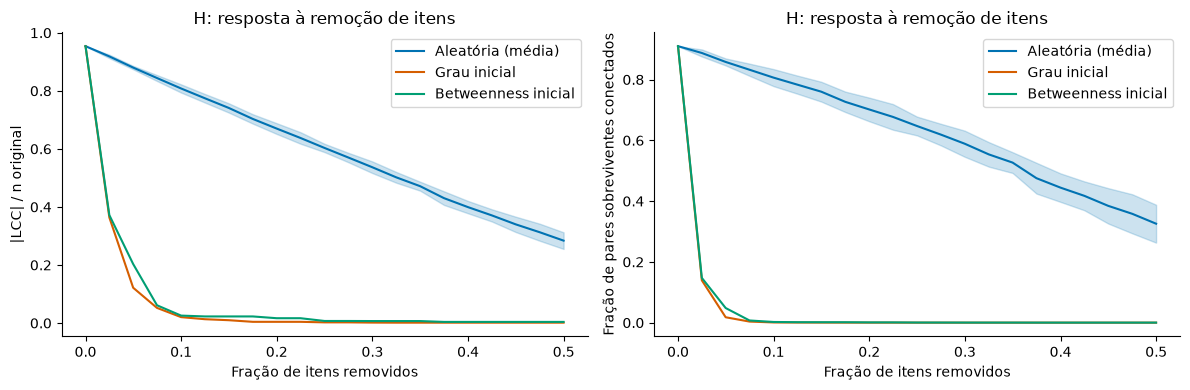

,lcc_original,connected_pairs,components,isolates
aleatória,0.808110,0.806337,221.4,152.9
grau,0.020408,0.000809,2575.0,2149.0
betweenness,0.025709,0.002381,2269.0,1909.0


**Robusta a falhas?** Após remover **10.0%** dos itens, a maior componente retém **80.8%** do total original sob falhas aleatórias, **2.0%** sob ataque por grau e **2.6%** por betweenness. A diferença quantifica a tolerância relativa a falhas distribuídas e a vulnerabilidade à perda dos itens que conectam muitas receitas. Não significa que todos os crafts da componente restante ainda sejam executáveis.

In [18]:
fractions = np.linspace(0, .5, 21)

def removal_curve(order):
    graph = H.copy()
    rows, removed = [], 0
    for fraction in fractions:
        target = int(fraction * len(H))
        graph.remove_nodes_from(order[removed:target])
        removed = target
        sizes = [len(c) for c in nx.connected_components(graph)]
        remaining = len(graph)
        rows.append({"fraction": target / len(H), "lcc_original": max(sizes, default=0) / len(H),
                     "connected_pairs": sum(s * (s-1) for s in sizes) / max(remaining * (remaining-1), 1),
                     "components": len(sizes), "isolates": nx.number_of_isolates(graph)})
    return pd.DataFrame(rows)

random_curves = []
for repetition in range(10):
    order = list(H)
    random.Random(SEED + repetition).shuffle(order)
    random_curves.append(removal_curve(order))
random_mean = pd.concat(random_curves).groupby("fraction").mean()
random_sd = pd.concat(random_curves).groupby("fraction").std()
degree_order = sorted(H, key=lambda v: (-H.degree(v), v))
between_order = sorted(H, key=lambda v: (-centralities.loc[v, "betweenness"], v))
target_degree = removal_curve(degree_order).set_index("fraction")
target_between = removal_curve(between_order).set_index("fraction")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, ylabel in zip(axes, ["lcc_original", "connected_pairs"],
                             ["|LCC| / n original", "Fração de pares sobreviventes conectados"]):
    x = random_mean.index.to_numpy()
    ax.plot(x, random_mean[metric], label="Aleatória (média)", color="#0072B2")
    ax.fill_between(x, (random_mean[metric]-random_sd[metric]).clip(lower=0),
                     (random_mean[metric]+random_sd[metric]).clip(upper=1), alpha=.2, color="#0072B2")
    ax.plot(target_degree.index, target_degree[metric], label="Grau inicial", color="#D55E00")
    ax.plot(target_between.index, target_between[metric], label="Betweenness inicial", color="#009E73")
    ax.set(xlabel="Fração de itens removidos", ylabel=ylabel, title="H: resposta à remoção de itens")
    ax.legend()
plt.tight_layout()
plt.show()
checkpoint = min(random_mean.index, key=lambda q: abs(q-.1))
robustness_at_10 = pd.DataFrame([random_mean.loc[checkpoint], target_degree.loc[checkpoint],
                                 target_between.loc[checkpoint]], index=["aleatória", "grau", "betweenness"])
display(robustness_at_10)
display(Markdown(f"**Robusta a falhas?** Após remover **{checkpoint:.1%}** dos itens, a maior componente "
                 f"retém **{random_mean.loc[checkpoint,'lcc_original']:.1%}** do total original sob falhas aleatórias, "
                 f"**{target_degree.loc[checkpoint,'lcc_original']:.1%}** sob ataque por grau e "
                 f"**{target_between.loc[checkpoint,'lcc_original']:.1%}** por betweenness. "
                 "A diferença quantifica a tolerância relativa a falhas distribuídas e a vulnerabilidade "
                 "à perda dos itens que conectam muitas receitas. Não significa que todos os crafts da "
                 "componente restante ainda sejam executáveis."))

## 12. Difusão, preservação e navegação
**Difusão** aqui significa alcance de informação por relações da base, não propagação física no jogo.
A eficiência global estimada E = média de 1/d considera pares desconectados com contribuição zero.
Uma difusão determinística, uma aresta por rodada, equivale às camadas de uma BFS em H.

**Preservação** avalia rotas alternativas: pontes, articulações e blocos biconexos.
Uma ponte é uma aresta sem rota alternativa; articulação é um nó cuja perda aumenta o número de
componentes. Esses indicadores complementam a curva de ataques, mas não medem armazenamento de dados.

**Navegação** usa caminhos mínimos e exemplos reais. Caminhos em H permitem percorrer dependências
nos dois sentidos para consulta. Caminhos dirigidos em G e G_full seguem relações, mas não resolvem
automaticamente todos os slots conjuntos, quantidades, estações ou progressão.

,indicador,valor
0,pontes,1548.000000
1,fração de arestas que são pontes,0.231321
2,articulações,446.000000
3,fração de vértices que são articulações,0.118208
4,maior bloco biconexo,2110.000000
5,ciclos independentes m-n+c,2981.000000
6,pares conectados (exato),0.909920
7,eficiência global (estimada),0.185780


,item A,item B
0,Ancient Blue Brick,Ancient Blue Brick Wall
1,Ancient Cobalt Brick,Ancient Cobalt Brick Wall
2,Ancient Copper Brick,Ancient Copper Brick Wall
3,Ancient Gold Brick,Ancient Gold Brick Wall
4,Ancient Green Brick,Ancient Green Brick Wall
5,Ancient Hellstone Brick,Ancient Hellstone Brick Wall


,nome,betweenness,degree
item:Torch,Torch,0.197152,0.090403
item:StoneBlock,Stone Block,0.135088,0.037116
item:Glass,Glass,0.131716,0.030488
item:Silk,Silk,0.100684,0.046925
item:LeadBar,Lead Bar,0.071258,0.048250
item:IronBar,Iron Bar,0.069873,0.048515
item:Terrarium,Terrarium,0.060282,0.017232
item:Bottle,Bottle,0.045938,0.012725


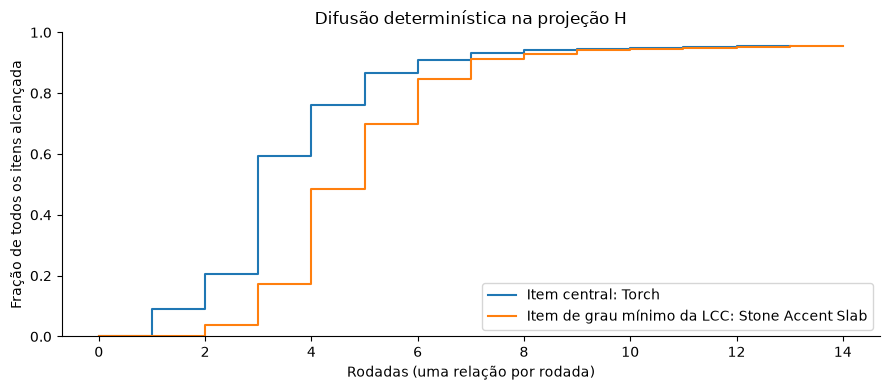

**A difusão é fácil?** Na maior componente, a distância média estimada é **5.66** relações. Porém somente **91.0%** dos pares de H são conectados; E ≈ **0.186**. A BFS iniciada em Torch alcança **95.4%** dos itens em **13** rodadas. Há acesso curto na região principal, mas a informação não atravessa componentes separadas.

**A preservação é fácil?** H contém **1548 pontes** (23.1% das arestas) e **446 articulações** (11.8% dos itens). Seu maior bloco biconexo tem **2110 itens**, e há **2981 ciclos independentes**. A redundância se concentra em parte da rede; ramos ligados por pontes têm uma única rota. Preservar acesso depende da posição do item, além da quantidade removida nos ataques.

In [19]:
bridges = list(nx.bridges(H))
articulations = sorted(nx.articulation_points(H))
blocks = list(nx.biconnected_components(H))
cycle_rank = H.number_of_edges() - len(H) + nx.number_connected_components(H)
reachable_pairs = sum(len(c)*(len(c)-1) for c in components_H) / (len(H)*(len(H)-1))
largest_block = max(blocks, key=len)
display(pd.DataFrame({
    "indicador": ["pontes", "fração de arestas que são pontes", "articulações",
                  "fração de vértices que são articulações", "maior bloco biconexo",
                  "ciclos independentes m-n+c", "pares conectados (exato)", "eficiência global (estimada)"],
    "valor": [len(bridges), len(bridges)/H.number_of_edges(), len(articulations), len(articulations)/len(H),
              len(largest_block), cycle_rank, reachable_pairs, real_metrics["efficiency"]]
}))
bridge_examples = sorted(bridges, key=lambda e: (H.degree(e[0])+H.degree(e[1]), e))[:6]
display(pd.DataFrame([{"item A": H.nodes[u]["name"], "item B": H.nodes[v]["name"]}
                      for u,v in bridge_examples]))
display(centralities.loc[articulations].nlargest(8, "betweenness")[["nome", "betweenness", "degree"]])

hub = top3.index[0]
peripheral = min(LCC, key=lambda node: (H.degree(node), node))
fig, ax = plt.subplots(figsize=(9, 4))
diffusion_summary = []
for label, origin in [("Item central", hub), ("Item de grau mínimo da LCC", peripheral)]:
    distances = nx.single_source_shortest_path_length(H, origin)
    counts = np.bincount(list(distances.values()))
    cumulative = np.cumsum(counts) / len(H)
    ax.step(range(len(cumulative)), cumulative, where="post", label=f"{label}: {H.nodes[origin]['name']}")
    diffusion_summary.append((H.nodes[origin]["name"], len(distances)/len(H), max(distances.values())))
ax.set(title="Difusão determinística na projeção H", xlabel="Rodadas (uma relação por rodada)",
       ylabel="Fração de todos os itens alcançada", ylim=(0,1))
ax.legend()
plt.tight_layout()
plt.show()
display(Markdown(f"**A difusão é fácil?** Na maior componente, a distância média estimada é "
                 f"**{real_metrics['distance_lcc']:.2f}** relações. Porém somente **{reachable_pairs:.1%}** "
                 f"dos pares de H são conectados; E ≈ **{real_metrics['efficiency']:.3f}**. "
                 f"A BFS iniciada em {diffusion_summary[0][0]} alcança **{diffusion_summary[0][1]:.1%}** "
                 f"dos itens em **{diffusion_summary[0][2]}** rodadas. Há acesso curto na região principal, "
                 "mas a informação não atravessa componentes separadas."))
display(Markdown(f"**A preservação é fácil?** H contém **{len(bridges)} pontes** "
                 f"({len(bridges)/H.number_of_edges():.1%} das arestas) e **{len(articulations)} articulações** "
                 f"({len(articulations)/len(H):.1%} dos itens). Seu maior bloco biconexo tem "
                 f"**{len(largest_block)} itens**, e há **{cycle_rank} ciclos independentes**. "
                 "A redundância se concentra em parte da rede; ramos ligados por pontes têm uma única rota. "
                 "Preservar acesso depende da posição do item, além da quantidade removida nos ataques."))

In [20]:
path_examples = []
for source, target in [("DemoniteOre", "TerraBlade"), ("ChlorophyteOre", "TerraBlade"),
                       ("IronOre", "IronPickaxe")]:
    path = nx.shortest_path(G, source, target)
    path_examples.append({"grafo": "G dirigido", "origem": G.nodes[source]["name"],
                           "destino": G.nodes[target]["name"], "passos": len(path)-1,
                           "caminho": " → ".join(G.nodes[n]["name"] for n in path)})
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(path_examples))
# Caminhos expandidos sem usar atalhos de catálogo ou associação indireta.
allowed = {"permite_encontro", "dropa", "vende", "ingrediente_de", "produz", "utilizada_em"}
navigation = nx.DiGraph()
navigation.add_edges_from((u,v) for u,v,d in G_full.edges(data=True) if d["relation"] in allowed)
start, finish = "biome:jungle", f"item:{recipes_desktop[bee_recipe]['result']}"
expanded_path = nx.shortest_path(navigation, start, finish)
display(Markdown("**Exemplo expandido:** " + " → ".join(G_full.nodes[n]["name"] for n in expanded_path) +
                 ". As relações do percurso são documentadas; ele ainda não lista todos os requisitos da receita."))
outside = sorted((n for n in H if n not in LCC), key=str)[0]
display(Markdown(f"**É fácil navegar?** H tem **{len(components_H)} componentes**. "
                 f"Por exemplo, **{H.nodes[outside]['name']}** está fora da componente de "
                 f"**{H.nodes[hub]['name']}**; não há caminho entre eles nessa projeção. "
                 "Nas regiões conectadas, BFS encontra rotas curtas e legíveis, como os exemplos acima. "
                 "A direção pode impedir o caminho inverso em G; os ciclos de conversão existentes são mantidos. "
                 "Navegar por relações é mais simples do que calcular um plano de crafting viável com todos os requisitos."))

,grafo,origem,destino,passos,caminho
0,G dirigido,Demonite Ore,Terra Blade,5,Demonite Ore → Demonite Bar → Light's Bane → Night's Edge → True Night's Edge → Terra Blade
1,G dirigido,Chlorophyte Ore,Terra Blade,3,Chlorophyte Ore → Chlorophyte Bar → True Excalibur → Terra Blade
2,G dirigido,Iron Ore,Iron Pickaxe,2,Iron Ore → Iron Bar → Iron Pickaxe


**Exemplo expandido:** Jungle → Queen Bee → Bee Wax → Receita 3567: Bee Headgear → Bee Headgear. As relações do percurso são documentadas; ele ainda não lista todos os requisitos da receita.

**É fácil navegar?** H tem **62 componentes**. Por exemplo, **Ancient Blue Brick** está fora da componente de **Torch**; não há caminho entre eles nessa projeção. Nas regiões conectadas, BFS encontra rotas curtas e legíveis, como os exemplos acima. A direção pode impedir o caminho inverso em G; os ciclos de conversão existentes são mantidos. Navegar por relações é mais simples do que calcular um plano de crafting viável com todos os requisitos.

## 13. Discussão dos resultados
As evidências anteriores respondem às cinco perguntas de avaliação. Os três itens destacados são
escolhidos por um critério explícito de centralidade; as curvas de remoção separam falhas aleatórias
de ataques; distância, eficiência, pontes e articulações sustentam as respostas sobre circulação,
redundância e navegação.

**Limitações da base:** não há mapa de geração de minérios; itens podem compartilhar IDs numéricos;
há variantes de criaturas sem correspondência inequívoca no bestiário. Biomas agregados não provam
mineração. Relações do catálogo incluem dificuldades, eventos e seeds diferentes, não um único mundo.
Itens não obtíveis e dados legados permanecem identificados como na fonte.

**Limitações de modelagem:** caminhos simples não implementam a lógica AND/OR de fabricação.
Agrupar fontes de boss não torna drops de sacolas diretos. Marcos do tracker estimam progressão
típica e não são uma lista completa de pré-requisitos do jogo. Condições de lojas e drops são textos
com lógica própria; os tokens não substituem sua interpretação. Mantemos os registros para consulta.

**Limitações estatísticas:** cinco realizações e amostragem de caminhos/intermediação têm incerteza.
WS/BA não igualam exatamente a densidade; Louvain depende de resolução e semente; a troca de arestas
não garante amostragem uniforme. O diagnóstico small-world não constitui teste de lei de potência.
A classificação acadêmica se refere a H, uma projeção de crafting, e não à totalidade do Terraria.

In [21]:
display(Markdown(
    f"**Síntese numérica:** G preserva **{len(G):,} itens e {G.number_of_edges():,} dependências**. "
    f"G_full reúne **{len(G_full):,} vértices e {G_full.number_of_edges():,} arestas**, "
    f"em **{len(node_counts)} tipos** e **{len(relation_counts)} relações**. "
    f"A projeção H tem **{len(H):,} vértices e {H.number_of_edges():,} arestas**; "
    f"clustering **{real_metrics['clustering']:.4f}**, assortatividade "
    f"**{real_metrics['assortativity']:.4f}** e grau médio **{real_metrics['mean_degree']:.2f}**. "
    f"Os três destaques pelo consenso declarado são **{', '.join(top3['nome'])}**. "
    + classification))
print(f"Tempo decorrido da análise: {time.perf_counter()-START:.1f} s (varia com a máquina).")
print("Células concluídas sem baixar dados ou gerar arquivos de resultados.")

**Síntese numérica:** G preserva **3,773 itens e 7,045 dependências**. G_full reúne **10,672 vértices e 28,710 arestas**, em **13 tipos** e **21 relações**. A projeção H tem **3,773 vértices e 6,692 arestas**; clustering **0.0323**, assortatividade **-0.2228** e grau médio **3.55**. Os três destaques pelo consenso declarado são **Torch, Stone Block, Iron Bar**. H tem traços small-world em relação a ER (clustering maior com caminhos relativamente curtos), mas esse diagnóstico precisa do controle de graus. O nulo de graus não confirma excesso de organização small-world: não há uma classificação inequívoca entre os três modelos.

Tempo decorrido da análise: 31.2 s (varia com a máquina).
Células concluídas sem baixar dados ou gerar arquivos de resultados.


## 14. Conclusões
O trabalho preserva a fabricação original e integra as relações comprovadas na fonte.
A comparação separa o catálogo heterogêneo da rede de dependências escolhida para a análise.
Os resultados mostram onde há concentração de conexões, rotas curtas, comunidades e fragilidade
a remoções, sem equiparar importância topológica a necessidade absoluta de um item.

Para apresentar: explicar primeiro uma receita com AND/OR, depois as três representações,
as centralidades e os exemplos reais; terminar com as comparações sintéticas e os experimentos de remoção.
As tabelas e os parágrafos calculados acima contêm os valores a citar.
A ausência de dados sobre geração de minérios e as limitações da projeção são parte da conclusão.